# UAV 語意分割

## 1. Environment Setting & hyperparameter

先確認 Python kernel、PyTorch 和 CUDA，再用 GPU 上一個小矩陣運算與反向傳播確認 CUDA 能真的執行。這一步沒有建立分割模型。

**本次 B10 使用第 1 節指定的 configs/segformer_b10_mitb4_512_80ep.yaml。** 裡面列出完整模型、資料切分、增強及訓練參數。

In [57]:
import csv
import ctypes
from collections import Counter, defaultdict
from dataclasses import dataclass
from datetime import datetime, timezone
import hashlib
from importlib.metadata import version
from itertools import islice
import json
import math
import os
from pathlib import Path, PurePosixPath
import platform
import random
import re
import subprocess
from tempfile import NamedTemporaryFile
from time import perf_counter
from uuid import uuid4
from zipfile import ZipFile

from IPython.display import Image as DisplayImage, display
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageDraw, ImageEnhance, ImageOps
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet34_Weights, resnet34
from torchvision.ops import StochasticDepth
import yaml

PROJECT = Path.cwd()
NUM_CLASSES = 16
OUTPUTS = PROJECT / "outputs"

In [58]:
def resize_wh(size):
    """設定採 [寬, 高]；舊版整數設定代表正方形。"""
    return (size, size) if isinstance(size, int) else tuple(size)


def merge(base: dict, override: dict) -> dict:
    result = base.copy()
    for key, value in override.items():
        if isinstance(result.get(key), dict) and isinstance(value, dict):
            result[key] = merge(result[key], value)
        else:
            result[key] = value
    return result


def project_path(value: str | Path) -> Path:
    return PROJECT / value


def system_memory():
    if os.name == "nt":
        class MemoryStatus(ctypes.Structure):
            _fields_ = [("length", ctypes.c_ulong), ("load", ctypes.c_ulong)] + [
                (name, ctypes.c_ulonglong) for name in
                ("total_physical", "available_physical", "total_page", "available_page",
                 "total_virtual", "available_virtual", "available_extended")
            ]
        status = MemoryStatus()
        status.length = ctypes.sizeof(status)
        if ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(status)):
            return status.total_physical
    elif hasattr(os, "sysconf"):
        try:
            return os.sysconf("SC_PHYS_PAGES") * os.sysconf("SC_PAGE_SIZE")
        except (OSError, ValueError):
            pass
    return None


def detected_nvidia_gpus():
    command = ["nvidia-smi", "--query-gpu=name,memory.total,memory.free",
               "--format=csv,noheader,nounits"]
    try:
        output = subprocess.run(command, check=True, capture_output=True,
                                text=True, timeout=3).stdout
        return [{"name": name, "vram_total_bytes": int(total) * 2**20,
                 "vram_free_bytes": int(free) * 2**20}
                for name, total, free in csv.reader(output.splitlines(), skipinitialspace=True)]
    except (OSError, ValueError, subprocess.SubprocessError):
        return []


def environment():
    cuda = torch.cuda.is_available()
    gpus = []
    if cuda:
        for index in range(torch.cuda.device_count()):
            free, total = torch.cuda.mem_get_info(index)
            gpus.append({"index": index, "name": torch.cuda.get_device_name(index),
                         "vram_total_bytes": total, "vram_free_bytes": free})
    return {"os": platform.platform(), "python": platform.python_version(),
            "torch": str(torch.__version__), "cuda_build": torch.version.cuda,
            "cuda_available": cuda, "cuda_devices": gpus,
            "nvidia_smi_devices": [] if cuda else detected_nvidia_gpus(),
            "package_versions": {package: version(package) for package in
                                 ("torchvision", "numpy", "Pillow", "PyYAML", "matplotlib")},
            "logical_cpus": os.cpu_count(), "system_memory_bytes": system_memory()}


def select_device(config, mode):
    value = config["device"]
    device = torch.device(("cuda" if torch.cuda.is_available() else "cpu")
                          if value == "auto" else value)
    if device.type not in {"cpu", "cuda"}:
        raise ValueError("Choose device auto, cpu or cuda")
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable in this PyTorch installation")
    if device.type == "cpu" and mode == "full" and not config["allow_full_cpu"]:
        raise RuntimeError("Full training requires CUDA by default. Use development mode "
                           "or explicitly set allow_full_cpu: true.")
    return device


def choose_batch_size(config, device):
    requested = config["training"]["batch_size"]
    width, height = resize_wh(config["image_size"])
    model = config["model"]["name"]
    variant = config["model"]["variant"]
    heavy = model == "segformer" and variant in {"b1", "b2", "b4"}
    # Activation heuristic at 512 px, with a separate allowance for model state.
    per_image = round((1.45 if heavy else 0.75) * 2**30 * (width * height / 512**2))
    if requested != "auto":
        batch = int(requested)
    elif device.type == "cpu":
        batch = 2
    else:
        free, _ = torch.cuda.mem_get_info(device)
        budget = int(free * 0.65)
        batch = min(12, (budget - 2**30) // max(1, per_image))
        if batch < 1:
            raise RuntimeError("The initial memory estimate exceeds available VRAM. "
                               "Reduce image_size or use SegFormer-B0.")
    return batch, {"activation_bytes_per_image_heuristic": per_image,
                   "batch_activation_bytes_heuristic": batch * per_image,
                   "model_and_workspace_reserve_bytes_heuristic": 2**30}


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

In [59]:
def timestamp():
    return datetime.now(timezone.utc).isoformat()


def write_json(path: Path, data):
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".tmp")
    temp.write_text(json.dumps(data, indent=2, allow_nan=False) + "\n", encoding="utf-8")
    temp.replace(path)


def read_json(path: Path):
    return json.loads(path.read_text(encoding="utf-8"))


def write_csv(path: Path, fields, rows):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=fields)
        writer.writeheader()
        writer.writerows(rows)

In [60]:
BASIC_AUGMENTATION = {
    "hflip": 0.5, "vflip": 0.0, "geometry_probability": 0.0, "rotation": 0,
    "scale": [1.0, 1.0], "crop_fraction": 1.0, "color_probability": 0.0,
    "color_jitter": 0.0, "brightness_contrast": 0.0, "noise_std": 0.0,
    "fog_probability": 0.0,
}
ADVANCED_AUGMENTATION = {
    **BASIC_AUGMENTATION, "vflip": 0.25, "geometry_probability": 0.6,
    "rotation": 12, "scale": [0.8, 1.2], "crop_fraction": 0.85,
    "color_probability": 0.6, "color_jitter": 0.15, "brightness_contrast": 0.2,
    "noise_std": 0.015,
}
STANDARD_INFERENCE = {
    "tile_size": None, "overlap": 0.25, "hflip": False, "vflip": False, "scales": [1.0],
}
TTA_INFERENCE = {"hflip": True, "vflip": False, "scales": [1.0]}  # B3：只比較水平翻轉


def experiment_config(mode, model_name, experiment=None, overrides=None):
    presets = {"E1": "unet", "E2": "unet", "E3": "unet", "E4": "segformer"}
    if mode not in {"debug", "development", "full"}:
        raise ValueError("Choose DEBUG, DEVELOPMENT or FULL")
    if experiment is not None and experiment not in presets:
        raise ValueError("Training experiment IDs are E1 through E4")
    if experiment is not None:
        model_name = presets[experiment]
    if model_name not in {"tiny", "unet", "segformer"} or (model_name == "tiny" and mode != "debug"):
        raise ValueError("Choose unet or segformer. The tiny CNN is available in DEBUG.")
    yaml_name = "unet" if model_name == "tiny" else model_name
    with (PROJECT / "configs" / f"{yaml_name}.yaml").open(encoding="utf-8") as stream:
        model_config = yaml.safe_load(stream)
    config = {
        **model_config, "seed": 42, "split_seed": 42, "val_fraction": 0.2,
        "normalize": True, "workers": 0, "device": "auto", "allow_full_cpu": False,
        "development_limit": 200, "experiment": experiment,
        "augmentation": (ADVANCED_AUGMENTATION if experiment in {"E3", "E4"}
                         else BASIC_AUGMENTATION),
        "inference": STANDARD_INFERENCE, "ensemble": [],
    }
    if experiment == "E1":
        config = merge(config, {"loss": {"name": "ce"}})
    if mode == "development":
        config = merge(config, {"image_size": 256, "training": {"epochs": 5, "warmup_epochs": 1}})
    if mode == "debug":
        config = merge(config, {
            "image_size": 64, "device": "cpu",
            "model": {"name": model_name, "variant": "b0", "pretrained": False,
                      "encoder_weights": None},
            "training": {"epochs": 2, "batch_size": 4, "warmup_epochs": 0,
                         "mixed_precision": False},
        })
    config = merge(config, overrides or {})
    if min(resize_wh(config["image_size"])) < 32:
        raise ValueError("Use an input size of at least 32 pixels.")
    return config

In [61]:
# B10 的所有超參數集中在這份 YAML。設定完成後到第 8 節手動開始。
EXPERIMENT_CONFIG = PROJECT / "configs/segformer_b10_mitb4_512_40ep.yaml"
with EXPERIMENT_CONFIG.open(encoding="utf-8") as stream:
    config = yaml.safe_load(stream)
seed_everything(config["seed"])
print(yaml.safe_dump({k: config[k] for k in ("experiment", "model", "image_size", "training", "loss", "augmentation")},
                     sort_keys=False))

experiment: B10_mitb4_512_80ep
model:
  name: segformer
  variant: b4
  pretrained: true
  encoder_weights: outputs/pretrained/nvidia-mit-b4.bin
image_size: 512
training:
  epochs: 40
  batch_size: 2
  accumulation: 2
  learning_rate: 0.0001
  weight_decay: 0.01
  warmup_epochs: 3
  clip_grad: 1.0
  patience: 15
  mixed_precision: true
loss:
  name: ce_dice
  dice_weight: 0.5
  class_weights: null
augmentation:
  hflip: 0.5
  vflip: 0.0
  geometry_probability: 0.0
  rotation: 0
  scale:
  - 1.0
  - 1.0
  crop_fraction: 1.0
  color_probability: 0.0
  color_jitter: 0.0
  brightness_contrast: 0.0
  noise_std: 0.0
  fog_probability: 0.0



In [62]:
resources = environment()
print(f"Python {resources['python']} | PyTorch {torch.__version__} | CUDA build {torch.version.cuda}")
print("CUDA available:", torch.cuda.is_available())
for gpu in resources["cuda_devices"] or resources["nvidia_smi_devices"]:
    print(gpu)
if torch.cuda.is_available():
    probe = torch.ones((32, 32), device="cuda", requires_grad=True)
    (probe @ probe).mean().backward()
    torch.cuda.synchronize()
    assert torch.isfinite(probe.grad).all().item()
    print(f"CUDA 實測通過：{torch.cuda.get_device_name(0)}｜"
          f"{torch.cuda.get_device_properties(0).total_memory / 2**30:.2f} GiB")
    del probe
else:
    print("CUDA 目前不可用。仍可用 CPU 查看資料，正式訓練前請先確認 CUDA 環境。")

Python 3.12.8 | PyTorch 2.11.0+cu128 | CUDA build 12.8
CUDA available: True
{'index': 0, 'name': 'NVIDIA GeForce RTX 5070 Ti', 'vram_total_bytes': 17066360832, 'vram_free_bytes': 11629756416}
CUDA 實測通過：NVIDIA GeForce RTX 5070 Ti｜15.89 GiB


## 2. Dataset Exploration

train/imgs 是 RGB 影像，train/masks 是各像素的真實類別，兩邊依檔名主體配對。test/imgs 是最後要預測的官方測試影像，沒有公開遮罩。這節先保留盤點用函式。第 3 節會列實際張數並顯示配對範例。需要逐張掃描及類別比例時，可執行第 4 節有註解的 audit_dataset。

In [63]:
PALETTE = np.array([
    [39, 59, 77], [195, 137, 93], [40, 129, 78], [187, 54, 76],
    [219, 183, 66], [58, 147, 198], [103, 67, 148], [161, 215, 85],
    [234, 128, 152], [114, 179, 161], [245, 225, 200], [122, 119, 104],
    [225, 99, 53], [79, 89, 187], [100, 217, 232], [163, 100, 184],
], dtype=np.uint8)


def save_figure(figure, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    figure.savefig(path, dpi=220, bbox_inches="tight")
    plt.close(figure)


def color_mask(mask):
    palette = np.zeros((256, 3), dtype=np.uint8)
    palette[:NUM_CLASSES] = PALETTE
    return palette[np.asarray(mask)]


def class_chart(values, ylabel, output):
    figure, axis = plt.subplots(figsize=(8, 3.3), layout="constrained")
    axis.bar(range(NUM_CLASSES), [np.nan if x is None else x for x in values], color="#3c8196")
    axis.set(xticks=range(NUM_CLASSES), xlabel="Class ID", ylabel=ylabel)
    save_figure(figure, output)


def panel(rows, headings, output, row_labels=None):
    figure, axes = plt.subplots(len(rows), len(headings), squeeze=False,
                               figsize=(3 * len(headings), 2.6 * len(rows)), layout="constrained")
    for row, images in enumerate(rows):
        for col, image in enumerate(images):
            axis = axes[row, col]
            axis.imshow(image, cmap="gray", vmin=0, vmax=15, interpolation="nearest")
            axis.set_xticks([])
            axis.set_yticks([])
            for spine in axis.spines.values():
                spine.set_visible(False)
            if row == 0:
                axis.set_title(headings[col])
            if col == 0 and row_labels:
                axis.set_ylabel(row_labels[row])
    save_figure(figure, output)

In [64]:
def describe_dimensions(sizes):
    if not sizes:
        return {"count": 0}
    counts = Counter(sizes)
    ratios = [w / h for w, h in sizes]
    return {"count": len(sizes),
            "resolutions": {f"{w}x{h}": count for (w, h), count in sorted(counts.items())},
            "aspect_ratio": {"minimum": min(ratios), "median": float(np.median(ratios)),
                             "maximum": max(ratios)}}


def audit_dataset(root, output, config, *, figure_dir=None):
    pairs = training_pairs(root)
    images = list_images(root / "test/imgs")
    present = np.zeros(NUM_CLASSES, dtype=np.int64)
    pixels = np.zeros(NUM_CLASSES, dtype=np.int64)
    sizes, test_sizes, examples, augmented, failures = [], [], [], [], []
    selected = set(random.Random(config["seed"]).sample(range(len(pairs)), min(4, len(pairs))))
    transform = SegmentationTransform(config["image_size"], config["normalize"],
                                      config["augmentation"])
    for index, pair in enumerate(pairs):
        try:
            image, mask = read_pair(pair)
        except (OSError, ValueError) as failure:
            failures.append(str(failure))
            continue
        sizes.append(image.size)
        labels = np.asarray(mask)
        histogram = np.bincount(labels.ravel(), minlength=NUM_CLASSES)
        present += histogram > 0
        pixels += histogram
        if index in selected:
            rgb, color = np.asarray(image), color_mask(labels)
            overlay = (0.55 * rgb + 0.45 * color).astype(np.uint8)
            examples.append([rgb, labels, color, overlay])
            changed_image, changed_mask = transform.prepare(image, mask)
            augmented.append([rgb, color, np.asarray(changed_image), color_mask(changed_mask)])
    for path in images:
        try:
            with Image.open(path) as source:
                source.load()
                test_sizes.append(source.size)
        except OSError as failure:
            failures.append(f"{path}: {failure}")
    summary = {"dataset": dataset_kind(root), "root": str(root), "train_pairs": len(pairs),
               "test_images": len(images), "training_dimensions": describe_dimensions(sizes),
               "test_dimensions": describe_dimensions(test_sizes), "errors": failures,
               "missing_class_ids": np.flatnonzero(present == 0).tolist()}
    write_json(output / "dataset_integrity.json", summary)
    if not pixels.sum():
        raise ValueError(f"No valid labeled pixels in {root}")
    rows = [
        {"class_id": label, "images_with_class": int(present[label]),
         "image_percentage": float(present[label] * 100 / len(sizes)),
         "pixels": int(pixels[label]), "pixel_percentage": float(pixels[label] * 100 / pixels.sum())}
        for label in range(NUM_CLASSES)
    ]
    write_csv(output / "tables/class_statistics.csv", list(rows[0]), rows)
    figures = figure_dir or output / "figures"
    class_chart(present, "Images containing class", figures / "class_image_frequency.png")
    class_chart([row["pixel_percentage"] for row in rows], "Labeled pixels (%)",
                figures / "class_pixel_frequency.png")
    panel(examples, ["RGB", "Grayscale labels", "Class colors", "Overlay"],
          figures / "dataset_examples.png")
    panel(augmented, ["Raw RGB", "Raw labels", "Transformed RGB", "Transformed labels"],
          figures / "augmentation_examples.png")
    return summary

## 3. Dataset & DataLoader

Dataset 定義「取一筆資料」的規則，DataLoader 則把多筆資料組成 batch。訓練資料只從官方有遮罩的 4,000 張資料切出 3,200 張訓練、800 張驗證。切分種子固定，因此改模型後仍可用相同驗證影像比較。官方測試 Dataset 回傳影像、檔名和原始高寬，供推論後還原大小，無須提供遮罩。

第 4 節會把前處理接到三個 DataLoader 上，逐一取一批並印出張量形狀。先看這些結果，再進入模型。

In [65]:
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}


DEBUG_MARKER = "DEBUG_ONLY.txt"


@dataclass(frozen=True)
class Pair:
    image: Path
    mask: Path


def resolve_root(path: Path) -> Path:
    parts = ("train/imgs", "train/masks", "test/imgs")
    if all((path / part).is_dir() for part in parts):
        return path
    matches = sorted({p.parent for p in path.rglob("train")
                      if all((p.parent / part).is_dir() for part in parts)})
    if len(matches) != 1:
        raise ValueError(f"Expected one dataset under {path}, found {len(matches)}")
    return matches[0]


def extract_dataset(archive: Path, destination: Path) -> Path:
    destination.mkdir(parents=True, exist_ok=False)
    with ZipFile(archive) as bundle:
        for entry in bundle.infolist():
            name = PurePosixPath(entry.filename.replace(chr(92), "/"))
            if (name.is_absolute() or ".." in name.parts
                    or any(":" in part for part in name.parts)
                    or not (destination / Path(*name.parts)).resolve().is_relative_to(
                        destination.resolve())):
                raise ValueError(f"Unsafe archive path: {entry.filename}")
        bundle.extractall(destination)
    return resolve_root(destination)


def list_images(directory: Path) -> list[Path]:
    return sorted(p for p in directory.iterdir() if p.is_file()
                  and p.suffix.lower() in IMAGE_EXTENSIONS)


def training_pairs(root: Path) -> list[Pair]:
    images = list_images(root / "train/imgs")
    masks = list_images(root / "train/masks")
    by_image = {p.stem: p for p in images}
    by_mask = {p.stem: p for p in masks}
    if len(by_image) != len(images) or len(by_mask) != len(masks):
        raise ValueError("Duplicate filename stems in training data")
    missing = sorted(by_image.keys() - by_mask.keys())
    extra = sorted(by_mask.keys() - by_image.keys())
    if missing or extra or not images:
        raise ValueError(f"Invalid pairing: {len(images)} images, "
                         f"missing masks {missing[:8]}, extra masks {extra[:8]}")
    return [Pair(image, by_mask[image.stem]) for image in images]


def read_pair(pair: Pair) -> tuple[Image.Image, Image.Image]:
    with Image.open(pair.image) as source:
        image = source.convert("RGB")
    with Image.open(pair.mask) as source:
        labels = np.array(source)
    if labels.ndim != 2 or image.size != labels.shape[::-1]:
        raise ValueError(f"Mask shape differs from image at {pair.mask}")
    if labels.dtype.kind not in "bui" or labels.min() < 0 or labels.max() >= NUM_CLASSES:
        raise ValueError(f"Invalid mask labels at {pair.mask}")
    return image, Image.fromarray(labels.astype(np.uint8))

In [66]:
def split_pairs(pairs: list[Pair], fraction: float, seed: int) -> tuple[list, list]:
    if len(pairs) < 2 or not 0 < fraction < 1:
        raise ValueError("Splitting needs at least two pairs and 0 < val_fraction < 1")
    shuffled = pairs.copy()
    random.Random(seed).shuffle(shuffled)
    count = min(len(pairs) - 1, max(1, round(len(pairs) * fraction)))
    return shuffled[count:], shuffled[:count]


def class_presence(pair: Pair) -> set[int]:
    with Image.open(pair.mask) as mask:
        return set(np.unique(np.asarray(mask)).tolist())


def development_subset(pairs: list[Pair], limit: int) -> list[Pair]:
    if limit < 1:
        raise ValueError("development_limit must be positive")
    selected = []
    missing = set(range(NUM_CLASSES))
    for pair in pairs:
        if not missing or len(selected) == limit:
            break
        present = class_presence(pair)
        if missing & present:
            selected.append(pair)
            missing -= present
    chosen = set(selected)
    selected.extend(pair for pair in pairs if pair not in chosen)
    return selected[:limit]


def dataset_kind(root: Path) -> str:
    return "debug" if (root / DEBUG_MARKER).is_file() else "official"


def require_official(root: Path) -> None:
    counts = (len(training_pairs(root)), len(list_images(root / "test/imgs")))
    if dataset_kind(root) != "official" or counts != (4000, 1000):
        raise ValueError(f"Official data requires 4,000 pairs and 1,000 tests, got {counts}")


class SegmentationDataset(Dataset):
    def __init__(self, pairs, transform):
        self.pairs = pairs
        self.transform = transform

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        pair = self.pairs[index]
        image, mask = read_pair(pair)
        image, mask = self.transform(image, mask)
        return image, mask, str(pair.image)


def make_loader(pairs, config, batch_size, device, *, training=False):
    transform = SegmentationTransform(config["image_size"], config["normalize"],
                                      config["augmentation"] if training else None)
    return DataLoader(SegmentationDataset(pairs, transform), batch_size=batch_size,
                      shuffle=training, num_workers=config["workers"],
                      pin_memory=device.type == "cuda")


def split_for_run(root, config, mode):
    train, validation = split_pairs(training_pairs(root), config["val_fraction"], config.get("split_seed", config["seed"]))
    if mode == "development":
        train = development_subset(train, config["development_limit"])
    return train, validation


def split_names(train, validation):
    return {"train": [pair.image.name for pair in train],
            "validation": [pair.image.name for pair in validation]}

訓練 3200 張｜驗證 800 張｜官方測試 1000 張
129.png：RGB (800, 600)｜遮罩 (600, 800)｜類別 [ 0  1  2  3  4  5  6  8 10 13]


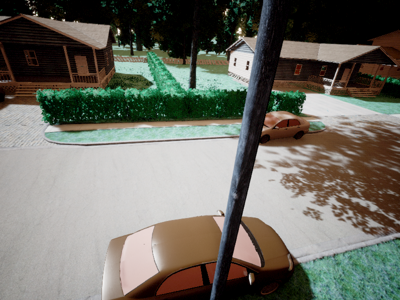

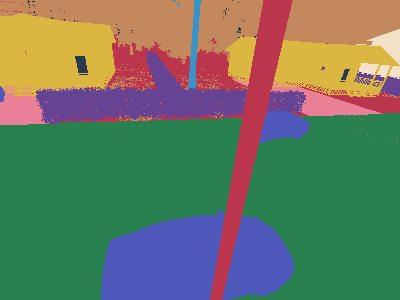

In [67]:
data_root = PROJECT / "UAV_dataset"
require_official(data_root)
train_pairs, val_pairs = split_for_run(data_root, config, "full")
test_images = list_images(data_root / "test/imgs")
assert not set(train_pairs) & set(val_pairs)
print(f"訓練 {len(train_pairs)} 張｜驗證 {len(val_pairs)} 張｜官方測試 {len(test_images)} 張")
image, mask = read_pair(train_pairs[0])
labels = np.asarray(mask)
print(f"{train_pairs[0].image.name}：RGB {image.size}｜遮罩 {labels.shape}｜類別 {np.unique(labels)}")
display(image.resize((400, 300)))
display(Image.fromarray(color_mask(labels)).resize((400, 300), Image.Resampling.NEAREST))

## 4. Preprocessing & Data Augmentation & Batch test

RGB 使用雙線性縮放，並按 ImageNet mean/std 正規化。遮罩使用最近鄰縮放，避免把整數類別混成其他數值。訓練時的翻轉同時作用在影像和遮罩，驗證與測試則只做固定前處理。

下面實際建立 train_loader、val_loader、test_loader。預設影像形狀應為 [2, 3, 512, 512]，訓練和驗證遮罩應為 [2, 512, 512] 且為 torch.int64。官方測試批次另外印出原圖尺寸。這一步只讀資料，不會執行模型。

**B10** 沿用 B7 的固定 512×512 縮放與訓練水平翻轉（50%），驗證時使用完整畫面。

In [68]:
MEAN = (0.485, 0.456, 0.406)


STD = (0.229, 0.224, 0.225)


BILINEAR = Image.Resampling.BILINEAR


NEAREST = Image.Resampling.NEAREST


def image_tensor(image: Image.Image, normalize: bool) -> torch.Tensor:
    data = np.array(image.convert("RGB"), dtype=np.float32) / 255.0
    if normalize:
        data = (data - np.array(MEAN, dtype=np.float32)) / np.array(STD, dtype=np.float32)
    return torch.from_numpy(data).permute(2, 0, 1).contiguous()


def spatial_transform(image, mask, settings):
    if random.random() < settings["hflip"]:
        image, mask = ImageOps.mirror(image), ImageOps.mirror(mask)
    if random.random() < settings["vflip"]:
        image, mask = ImageOps.flip(image), ImageOps.flip(mask)
    if random.random() >= settings["geometry_probability"]:
        return image, mask
    angle = random.uniform(-settings["rotation"], settings["rotation"])
    scale = random.uniform(*settings["scale"])
    size = tuple(max(1, round(edge * scale)) for edge in image.size)
    image = image.resize(size, BILINEAR).rotate(angle, BILINEAR, fillcolor=(0, 0, 0))
    mask = mask.resize(size, NEAREST).rotate(angle, NEAREST, fillcolor=255)
    width, height = size
    fraction = settings["crop_fraction"]
    crop_w, crop_h = max(1, int(width * fraction)), max(1, int(height * fraction))
    left = random.randint(0, width - crop_w)
    top = random.randint(0, height - crop_h)
    box = (left, top, left + crop_w, top + crop_h)
    return image.crop(box), mask.crop(box)


def color_transform(image, settings):
    if random.random() < settings["color_probability"]:
        color = settings["color_jitter"]
        amount = settings["brightness_contrast"]
        image = ImageEnhance.Color(image).enhance(random.uniform(1 - color, 1 + color))
        image = ImageEnhance.Brightness(image).enhance(random.uniform(1 - amount, 1 + amount))
        image = ImageEnhance.Contrast(image).enhance(random.uniform(1 - amount, 1 + amount))
        if settings["noise_std"] > 0:
            data = np.asarray(image).astype(np.float32)
            data += np.random.normal(0, settings["noise_std"] * 255, data.shape)
            image = Image.fromarray(data.clip(0, 255).astype(np.uint8))
    if random.random() < settings["fog_probability"]:
        image = Image.blend(image, Image.new("RGB", image.size, (226, 232, 237)),
                            random.uniform(0.12, 0.38))
    return image

In [69]:
def boundary_crop_box(mask, size, pairs):
    """在可用的目標類別對中隨機選一對，以四鄰域交界為中心裁切。"""
    width, height = mask.size
    w, h = size
    if width < w or height < h:
        return None
    labels = np.asarray(mask)
    for a, b in random.sample(pairs, len(pairs)):
        edge = np.zeros(labels.shape, dtype=bool)
        for left, right in ((labels[:, :-1], labels[:, 1:]), (labels[:-1], labels[1:])):
            adjacent = ((left == a) & (right == b)) | ((left == b) & (right == a))
            edge[:left.shape[0], :left.shape[1]] |= adjacent
        candidates = np.flatnonzero(edge)
        if candidates.size:
            y, x = divmod(int(random.choice(candidates)), width)
            x = min(max(0, x - w // 2), width - w)
            y = min(max(0, y - h // 2), height - h)
            return x, y, x + w, y + h
    return None


class SegmentationTransform:
    def __init__(self, size: int, normalize: bool, augmentation=None):
        self.size = resize_wh(size)
        self.normalize = normalize
        self.augmentation = augmentation

    def prepare(self, image, mask):
        if self.augmentation and self.augmentation.get("boundary_crop_probability", 0) > 0:
            if random.random() < self.augmentation["boundary_crop_probability"]:
                box = boundary_crop_box(mask, self.size, self.augmentation["boundary_pairs"])
                if box is not None:
                    image, mask = image.crop(box), mask.crop(box)
        # B4：在原始影像與遮罩上取相同位置，只做一次縮放以保留裁切區域的細節。
        if self.augmentation and self.augmentation.get("native_crop_probability", 0) > 0:
            if random.random() < self.augmentation["native_crop_probability"]:
                fraction = random.uniform(self.augmentation["native_crop_min_fraction"], 1.0)
                width, height = image.size
                w, h = max(1, round(width * fraction)), max(1, round(height * fraction))
                left, top = random.randint(0, width - w), random.randint(0, height - h)
                box = (left, top, left + w, top + h)
                image, mask = image.crop(box), mask.crop(box)
        image = image.resize(self.size, BILINEAR)
        mask = mask.resize(self.size, NEAREST)
        if self.augmentation is not None:
            image, mask = spatial_transform(image, mask, self.augmentation)
            width, height = image.size
            canvas_w, canvas_h = self.size
            if width < canvas_w or height < canvas_h:
                pad_w, pad_h = max(0, canvas_w - width), max(0, canvas_h - height)
                pad = (pad_w // 2, pad_h // 2, pad_w - pad_w // 2, pad_h - pad_h // 2)
                image = ImageOps.expand(image, pad, fill=(0, 0, 0))
                mask = ImageOps.expand(mask, pad, fill=255)
            width, height = image.size
            left = random.randint(0, width - canvas_w)
            top = random.randint(0, height - canvas_h)
            box = (left, top, left + canvas_w, top + canvas_h)
            image, mask = image.crop(box), mask.crop(box)
            image = color_transform(image, self.augmentation)
        return image, mask

    def __call__(self, image, mask):
        image, mask = self.prepare(image, mask)
        labels = torch.from_numpy(np.array(mask, dtype=np.int64))
        return image_tensor(image, self.normalize), labels

In [70]:
class UAVTestDataset(Dataset):
    def __init__(self, paths, settings):
        self.paths = paths
        self.size = resize_wh(settings["image_size"])
        self.normalize = settings["normalize"]

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        with Image.open(path) as source:
            height, width = source.height, source.width
            image = source.convert("RGB").resize(self.size, BILINEAR)
        return image_tensor(image, self.normalize), path.name, torch.tensor([height, width])


loader_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
batch_size, _ = choose_batch_size(config, loader_device)
train_loader = make_loader(train_pairs, config, batch_size, loader_device, training=True)
val_loader = make_loader(val_pairs, config, batch_size, loader_device)
test_dataset = UAVTestDataset(test_images, config)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                         pin_memory=loader_device.type == "cuda")

for name, loader in (("訓練", train_loader), ("驗證", val_loader)):
    images, labels, paths = next(iter(loader))
    assert images.shape[1:] == (3, *resize_wh(config["image_size"])[::-1])
    assert labels.shape == (images.shape[0], *images.shape[-2:])
    assert labels.dtype == torch.int64
    allowed = ((labels >= 0) & (labels < NUM_CLASSES)) | (labels == 255)
    assert allowed.all().item()
    print(f"{name}：影像 {tuple(images.shape)} {images.dtype}｜遮罩 {tuple(labels.shape)} {labels.dtype}")
images, names, original_hw = next(iter(test_loader))
assert images.shape[1:] == (3, *resize_wh(config["image_size"])[::-1])
assert images.shape[0] == len(names) == len(original_hw)
print(f"測試：影像 {tuple(images.shape)}｜檔名 {list(names)}｜原始高寬 {original_hw.tolist()}")
# 選做：掃描全部正式資料、畫類別分布和範例。
# audit_dataset(data_root, OUTPUTS / "logs/official_audit", config)

訓練：影像 (2, 3, 512, 512) torch.float32｜遮罩 (2, 512, 512) torch.int64
驗證：影像 (2, 3, 512, 512) torch.float32｜遮罩 (2, 512, 512) torch.int64
測試：影像 (2, 3, 512, 512)｜檔名 ['4000.png', '4001.png']｜原始高寬 [[600, 800], [600, 800]]


## 5. Model Architecture and choosing

在第 1 節指定的實驗 YAML 設定 model.name。unet 是 ResNet34 U-Net 基準。segformer 是多尺度 Transformer，可在 實驗 YAML 的 model.variant 選 b0、b1、b2、b4。B0 較小，B2 參數和顯存需求較高。訓練函式會依這個選擇建立模型。兩者輸入 [N, 3, H, W]，輸出 [N, 16, H, W]，因此可以共用資料、loss 與驗證流程。

### ResNet34 U-Net

編碼器逐層壓低解析度並提取特徵。解碼器把特徵上採樣，與同尺度編碼器特徵拼接，有助於恢復物件邊界。最後用 1×1 卷積輸出每個像素的 16 類分數。

In [71]:
class DecoderBlock(nn.Module):
    def __init__(self, incoming, skip_channels, outgoing):
        super().__init__()
        self.convolutions = nn.Sequential(
            nn.Conv2d(incoming + skip_channels, outgoing, 3, padding=1, bias=False),
            nn.BatchNorm2d(outgoing),
            nn.ReLU(inplace=True),
            nn.Conv2d(outgoing, outgoing, 3, padding=1, bias=False),
            nn.BatchNorm2d(outgoing),
            nn.ReLU(inplace=True),
        )

    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.convolutions(torch.cat((x, skip), dim=1))


class UNet(nn.Module):
    def __init__(self, classes, pretrained=False, encoder_weights=None):
        super().__init__()
        weights = ResNet34_Weights.DEFAULT if pretrained and not encoder_weights else None
        encoder = resnet34(weights=weights)
        if encoder_weights:
            encoder.load_state_dict(torch.load(encoder_weights, map_location="cpu", weights_only=True))
        self.stem = nn.Sequential(encoder.conv1, encoder.bn1, encoder.relu)
        self.pool = encoder.maxpool
        self.stages = nn.ModuleList([encoder.layer1, encoder.layer2, encoder.layer3, encoder.layer4])
        self.decoder = nn.ModuleList([
            DecoderBlock(512, 256, 256), DecoderBlock(256, 128, 128),
            DecoderBlock(128, 64, 64), DecoderBlock(64, 64, 32),
        ])
        self.classifier = nn.Conv2d(32, classes, 1)

    def forward(self, image):
        stem = self.stem(image)
        skips = [stem]
        x = self.pool(stem)
        for stage in self.stages:
            x = stage(x)
            skips.append(x)
        for block, skip in zip(self.decoder, reversed(skips[:-1]), strict=True):
            x = block(x, skip)
        return F.interpolate(self.classifier(x), size=image.shape[-2:],
                             mode="bilinear", align_corners=False)

### SegFormer B0／B1／B2

MiT 編碼器用四階段注意力提取多尺度資訊。解碼器把四個尺度投影並對齊後融合，再輸出 16 類。想先確認 Transformer 流程時可以選 B0，之後再比較 B2。

In [72]:
VARIANTS = {
    "b0": ((32, 64, 160, 256), (2, 2, 2, 2), 256),
    "b1": ((64, 128, 320, 512), (2, 2, 2, 2), 256),
    "b2": ((64, 128, 320, 512), (3, 4, 6, 3), 768),
    "b4": ((64, 128, 320, 512), (3, 8, 27, 3), 768),
}


HEADS = (1, 2, 5, 8)


REDUCTIONS = (8, 4, 2, 1)


def tokens_to_map(tokens, height, width):
    return tokens.transpose(1, 2).reshape(tokens.shape[0], tokens.shape[2], height, width)


class EfficientAttention(nn.Module):
    def __init__(self, channels, heads, reduction):
        super().__init__()
        self.heads = heads
        self.query = nn.Linear(channels, channels)
        self.key_value = nn.Linear(channels, 2 * channels)
        self.output = nn.Linear(channels, channels)
        self.reduce = nn.Conv2d(channels, channels, reduction, stride=reduction) if reduction > 1 else None
        self.norm = nn.LayerNorm(channels) if self.reduce is not None else nn.Identity()

    def split_heads(self, tokens):
        batch, length, channels = tokens.shape
        return tokens.reshape(batch, length, self.heads, channels // self.heads).transpose(1, 2)

    def forward(self, tokens, height, width):
        source = tokens
        if self.reduce is not None:
            features = self.reduce(tokens_to_map(tokens, height, width))
            source = self.norm(features.flatten(2).transpose(1, 2))
        key, value = self.key_value(source).chunk(2, dim=-1)
        attended = F.scaled_dot_product_attention(
            self.split_heads(self.query(tokens)), self.split_heads(key), self.split_heads(value)
        )
        return self.output(attended.transpose(1, 2).reshape_as(tokens))


class MixFFN(nn.Module):
    def __init__(self, channels):
        super().__init__()
        hidden = channels * 4
        self.expand = nn.Linear(channels, hidden)
        self.spatial = nn.Conv2d(hidden, hidden, 3, padding=1, groups=hidden)
        self.project = nn.Linear(hidden, channels)

    def forward(self, tokens, height, width):
        features = tokens_to_map(self.expand(tokens), height, width)
        mixed = self.spatial(features).flatten(2).transpose(1, 2)
        return self.project(F.gelu(mixed))


class TransformerBlock(nn.Module):
    def __init__(self, channels, heads, reduction, drop_path):
        super().__init__()
        self.attention_norm = nn.LayerNorm(channels)
        self.attention = EfficientAttention(channels, heads, reduction)
        self.ffn_norm = nn.LayerNorm(channels)
        self.ffn = MixFFN(channels)
        self.drop_path = StochasticDepth(drop_path, "row")

    def forward(self, tokens, height, width):
        tokens = tokens + self.drop_path(self.attention(self.attention_norm(tokens), height, width))
        return tokens + self.drop_path(self.ffn(self.ffn_norm(tokens), height, width))

In [73]:
def mit_encoder_state(state):
    """將 NVIDIA MiT 的參數名稱對應到本 notebook 的 encoder。"""
    if "segformer.encoder.patch_embeddings.0.proj.weight" not in state:
        return state  # 也支援原本的本地 encoder state_dict
    layers = {
        "layer_norm_1": "attention_norm", "layer_norm_2": "ffn_norm",
        "attention.self.query": "attention.query", "attention.self.sr": "attention.reduce",
        "attention.self.layer_norm": "attention.norm", "attention.output.dense": "attention.output",
        "mlp.dense1": "ffn.expand", "mlp.dwconv.dwconv": "ffn.spatial", "mlp.dense2": "ffn.project",
    }
    converted = {}
    for key, value in state.items():
        if key.startswith("classifier."):
            continue
        group, stage, rest = key.removeprefix("segformer.encoder.").split(".", 2)
        if group == "patch_embeddings":
            layer, param = rest.split(".")
            target = {"proj": "patch", "layer_norm": "patch_norm"}[layer] + "." + param
        elif group == "layer_norm":
            target = "output_norm." + rest
        elif group == "block":
            block, rest = rest.split(".", 1)
            layer, param = rest.rsplit(".", 1)
            if layer == "attention.self.value":
                continue  # key、value 由下一個分支合併成同一個 Linear
            if layer == "attention.self.key":
                value = torch.cat([value, state[key.replace(".self.key.", ".self.value.")]], dim=0)
                mapped = "attention.key_value"
            else:
                mapped = layers[layer]
            target = f"blocks.{block}.{mapped}.{param}"
        else:
            raise ValueError(f"Unknown MiT encoder group: {group}")
        converted[f"{stage}.{target}"] = value
    return converted


class MiTStage(nn.Module):
    def __init__(self, incoming, channels, heads, reduction, stride, drop_rates):
        super().__init__()
        kernel = 7 if stride == 4 else 3
        self.patch = nn.Conv2d(incoming, channels, kernel, stride=stride, padding=kernel // 2)
        self.patch_norm = nn.LayerNorm(channels)
        self.blocks = nn.ModuleList(
            TransformerBlock(channels, heads, reduction, rate) for rate in drop_rates
        )
        self.output_norm = nn.LayerNorm(channels)

    def forward(self, x):
        x = self.patch(x)
        height, width = x.shape[-2:]
        tokens = self.patch_norm(x.flatten(2).transpose(1, 2))
        for block in self.blocks:
            tokens = block(tokens, height, width)
        return tokens_to_map(self.output_norm(tokens), height, width)


class SegFormer(nn.Module):
    def __init__(self, classes, variant="b2", encoder_weights=None, residual=False):
        super().__init__()
        channels, depths, head_width = VARIANTS[variant]
        rates = torch.linspace(0, 0.1, sum(depths)).tolist()
        self.encoder = nn.ModuleList()
        for i, width in enumerate(channels):
            start = sum(depths[:i])
            self.encoder.append(MiTStage(
                3 if i == 0 else channels[i - 1], width, HEADS[i], REDUCTIONS[i],
                4 if i == 0 else 2, rates[start:start + depths[i]],
            ))
        if residual:
            from residual_refinement import ResidualRefinement
            self.refinement = ResidualRefinement(head_width, classes)
        self.projections = nn.ModuleList(nn.Linear(width, head_width) for width in channels)
        self.fusion = nn.Sequential(
            nn.Conv2d(4 * head_width, head_width, 1, bias=False),
            nn.BatchNorm2d(head_width), nn.ReLU(inplace=True), nn.Dropout2d(0.1),
            nn.Conv2d(head_width, classes, 1),
        )
        if encoder_weights:
            state = torch.load(encoder_weights, map_location="cpu", weights_only=True)
            self.encoder.load_state_dict(mit_encoder_state(state), strict=True)
            print(f"已完整載入 {variant.upper()} encoder 權重：{encoder_weights}")

    def forward(self, image):
        if min(image.shape[-2:]) < 32:
            raise ValueError("SegFormer needs input height and width of at least 32")
        x = image
        projected = []
        for stage, projection in zip(self.encoder, self.projections, strict=True):
            x = stage(x)
            height, width = x.shape[-2:]
            tokens = projection(x.flatten(2).transpose(1, 2))
            projected.append(tokens_to_map(tokens, height, width))
        fused_size = projected[0].shape[-2:]
        aligned = [F.interpolate(feature, size=fused_size, mode="bilinear", align_corners=False)
                   for feature in reversed(projected)]
        features = torch.cat(aligned, dim=1)
        if hasattr(self, "refinement"):
            semantic = self.fusion[:3](features)
            logits = self.fusion[4](self.fusion[3](semantic))
            base = F.interpolate(logits, size=image.shape[-2:], mode="bilinear", align_corners=False)
            return base + self.refinement(image, semantic)
        logits = self.fusion(features)
        return F.interpolate(logits, size=image.shape[-2:], mode="bilinear", align_corners=False)

### Model Creation

create_model() 讀取設定並建立對應架構。這個程式格只定義函式。若想自己印出模型，可在下一個程式格執行 print(create_model(config['model']))。

B10 使用 NVIDIA MiT-B4 的 ImageNet 預訓練 encoder。原始分類頭略去，16 類分割頭隨機初始化，兩部分一起訓練。權重檔放在第 1 節指定的路徑；換電腦可從[固定版本下載](https://huggingface.co/nvidia/mit-b4/resolve/3844ddaa13d9ce98816bacb904688a5284f164af/pytorch_model.bin)，另存為 nvidia-mit-b4.bin。

In [74]:
def create_model(config: dict, *, initialize_pretrained=True) -> nn.Module:
    name = config["name"]
    if name == "swin_upernet_residual":
        from swin_upernet_model import SwinUPerNetResidual
        return SwinUPerNetResidual(config, NUM_CLASSES, initialize_pretrained)
    pretrained = initialize_pretrained and config.get("pretrained", False)
    weights = config.get("encoder_weights") if initialize_pretrained else None
    weights = project_path(weights) if weights else None
    if name == "unet":
        return UNet(NUM_CLASSES, pretrained, weights)
    if name == "segformer":
        if pretrained and not weights:
            raise ValueError("SegFormer pretraining requires a local MiT encoder state dict")
        return SegFormer(NUM_CLASSES, config["variant"], weights, config.get("high_resolution_residual", False))
    if name == "tiny":
        return nn.Sequential(
            nn.Conv2d(3, 24, 5, padding=2), nn.ReLU(),
            nn.Conv2d(24, 24, 3, padding=1), nn.ReLU(),
            nn.Conv2d(24, NUM_CLASSES, 1),
        )
    raise ValueError(f"Unknown model: {name}")


def model_summary(model, config, image_size):
    summary = {
        "architecture": config["name"],
        "input_shape": [None, 3, *resize_wh(image_size)[::-1]],
        "logits_shape": [None, NUM_CLASSES, *resize_wh(image_size)[::-1]],
        "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "modules": str(model),
    }
    if config["name"] == "segformer":
        channels, depths, width = VARIANTS[config["variant"]]
        summary.update(variant=config["variant"], encoder_channels=channels,
                       encoder_depths=depths, decoder_width=width)
    return summary

## 6. Loss Function

Cross Entropy 衡量每個有標籤像素的分類誤差。Dice 衡量預測區域和真實區域的重疊程度。預設 CE + 0.5 × Dice，填充像素 255 會被忽略。loss 權重可在模型 YAML 的 loss 區塊修改。

In [75]:
IGNORE_INDEX = 255


class SegmentationLoss(nn.Module):
    def __init__(self, name, dice_weight=0.5, class_weights=None, boundary_weight=2.0, interior_weight=1.0):
        super().__init__()
        if name not in {"ce", "dice", "ce_dice", "weighted_ce", "boundary_ce_dice"}:
            raise ValueError(f"Unknown loss: {name}")
        if name == "weighted_ce" and class_weights is None:
            raise ValueError("weighted_ce requires class_weights")
        if class_weights is not None and (
            len(class_weights) != NUM_CLASSES or min(class_weights) <= 0
        ):
            raise ValueError("class_weights must contain 16 positive values")
        if dice_weight < 0:
            raise ValueError("dice_weight must be nonnegative")
        if name == "boundary_ce_dice" and (class_weights is not None or min(boundary_weight, interior_weight) <= 0):
            raise ValueError("Boundary CE requires positive pixel weights and no class weights")
        self.boundary_weight = boundary_weight
        self.interior_weight = interior_weight
        self.name = name
        self.dice_weight = dice_weight
        weights = torch.tensor(class_weights, dtype=torch.float32) if class_weights else None
        self.register_buffer("weights", weights)

    def forward(self, logits, target):
        valid = target != IGNORE_INDEX
        if not valid.any():
            return logits.sum() * 0.0
        logits = logits.float()
        if self.name != "dice":
            if self.name == "boundary_ce_dice":
                horizontal = valid[:, :, 1:] & valid[:, :, :-1] & (target[:, :, 1:] != target[:, :, :-1])
                vertical = valid[:, 1:, :] & valid[:, :-1, :] & (target[:, 1:, :] != target[:, :-1, :])
                boundary = torch.zeros_like(valid)
                boundary[:, :, 1:] |= horizontal
                boundary[:, :, :-1] |= horizontal
                boundary[:, 1:, :] |= vertical
                boundary[:, :-1, :] |= vertical
                band = F.max_pool2d(boundary[:, None].float(), 3, stride=1, padding=1)[:, 0] > 0
                weights = torch.where(band, self.boundary_weight, self.interior_weight) * valid
                pixel_ce = F.cross_entropy(logits, target, ignore_index=IGNORE_INDEX, reduction="none")
                ce = (pixel_ce * weights).sum() / weights.sum()
            else:
                ce = F.cross_entropy(logits, target, weight=self.weights, ignore_index=IGNORE_INDEX)
            if self.name in {"ce", "weighted_ce"} or self.dice_weight == 0:
                return ce
        labels = F.one_hot(target.masked_fill(~valid, 0), NUM_CLASSES).movedim(-1, 1)
        labels = labels * valid[:, None]
        probabilities = logits.softmax(dim=1) * valid[:, None]
        axes = (0, 2, 3)
        totals = labels.sum(dim=axes)
        intersection = (probabilities * labels).sum(dim=axes)
        present = totals > 0
        dice = 1 - ((2 * intersection[present] + 1e-6)
                    / (probabilities.sum(dim=axes)[present] + totals[present] + 1e-6)).mean()
        return dice if self.name == "dice" else ce + self.dice_weight * dice

## 7.  Validation Metrics

IoU 是某類別預測與標註的交集除以聯集。逐影像 mIoU 先對每張圖的有效類別取平均，再對影像取平均。全域 mIoU 先彙整所有像素的混淆矩陣才計算。聯集為零的類別不納入平均。訓練以逐影像 mIoU 選擇最佳 checkpoint。

In [76]:
def confusion_matrix(target, prediction):
    valid = target != IGNORE_INDEX
    indices = NUM_CLASSES * target[valid].astype(np.int64) + prediction[valid].astype(np.int64)
    return np.bincount(indices, minlength=NUM_CLASSES ** 2).reshape(NUM_CLASSES, NUM_CLASSES)


def iou_values(matrix):
    hits = matrix.diagonal()
    union = matrix.sum(0) + matrix.sum(1) - hits
    return np.divide(hits, union, out=np.full(NUM_CLASSES, np.nan), where=union > 0)


def mean_iou(values):
    valid = np.isfinite(values)
    return float(np.mean(values[valid])) if valid.any() else None


class SegmentationMetrics:
    def __init__(self):
        self.matrix = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
        self.per_image = []

    def add(self, target, prediction, name):
        matrix = confusion_matrix(target, prediction)
        self.matrix += matrix
        score = mean_iou(iou_values(matrix))
        self.per_image.append({"image": str(name), "miou": score})
        return matrix, score

    def summary(self):
        classes = iou_values(self.matrix)
        accuracy = float(np.trace(self.matrix) / self.matrix.sum()) if self.matrix.sum() else None
        return {
            "image_miou": mean_iou(np.array([r["miou"] for r in self.per_image
                                             if r["miou"] is not None])),
            "global_miou": mean_iou(classes),
            "pixel_accuracy": accuracy,
            "per_class_iou": [float(x) if np.isfinite(x) else None for x in classes],
            "confusion_matrix": self.matrix.tolist(),
            "per_image": self.per_image,
        }

In [77]:
def boundary_pixels(target):
    boundary = np.zeros(target.shape, dtype=bool)
    horizontal = target[:, 1:] != target[:, :-1]
    vertical = target[1:, :] != target[:-1, :]
    boundary[:, 1:] |= horizontal
    boundary[:, :-1] |= horizontal
    boundary[1:, :] |= vertical
    boundary[:-1, :] |= vertical
    return boundary


def add_metrics(metrics, image_path, target, prediction):
    matrix, _ = metrics.add(target, prediction, Path(image_path).name)
    boundary = boundary_pixels(target)
    wrong = target != prediction
    wrong_pairs = matrix.copy()
    np.fill_diagonal(wrong_pairs, 0)
    metrics.per_image[-1].update(
        boundary_error=float(wrong[boundary].mean()) if boundary.any() else None,
        confused_pixels=int(wrong_pairs.max()),
        targets=matrix.sum(1).tolist(),
        missed=(matrix.sum(1) - matrix.diagonal()).tolist(),
    )


@torch.inference_mode()
def validate_epoch(model, loader, loss_function, device):
    model.eval()
    metrics = SegmentationMetrics()
    loss_total = 0.0
    for images, targets, paths in loader:
        images, labels = images.to(device), targets.to(device)
        logits = model(images)
        loss_total += loss_function(logits, labels).item() * len(paths)
        for target, prediction, path in zip(targets.numpy(), logits.argmax(1).cpu().numpy(), paths,
                                            strict=True):
            add_metrics(metrics, path, target, prediction)
    summary = metrics.summary()
    summary["val_loss"] = loss_total / len(loader.dataset)
    summary["evaluation_size"] = "configured input resolution"
    return summary

## 8. Training and Validation Functions

每批先算 logits 與 loss，再反向傳播。預設每 2 個批次更新一次參數，有效 batch 約為 4。CUDA AMP 以混合精度降低顯存使用。AdamW 使用 warmup 和 cosine 衰減，每輪驗證後更新最佳分數，預設連續 15 輪沒有改善時提前結束。

### Output Directories

每次訓練產生一個 run ID，同一 ID 用來對照 checkpoints、logs 和 figures。epochs.csv 每輪記錄 loss、mIoU 與學習率。

In [78]:
def save_checkpoint(path: Path, state):
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".tmp")
    torch.save(state, temp)
    temp.replace(path)


def load_checkpoint(path: Path):
    return torch.load(path, map_location="cpu", weights_only=True)


def new_run(output_root, name):
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    run = output_root / "logs" / f"{stamp}_{name}_{uuid4().hex[:6]}"
    run.mkdir(parents=True, exist_ok=False)
    return run


def output_for(run, category):
    return run.parent.parent / category / run.name

In [79]:
def learning_rate_factor(step, warmup, total):
    if step < warmup:
        return (step + 1) / warmup
    fraction = (step - warmup) / max(1, total - warmup - 1)
    return 0.5 * (1 + math.cos(math.pi * min(1.0, fraction)))


def train_epoch(model, loader, loss_function, optimizer, scheduler, scaler, config, device):
    model.train()
    total = 0.0
    batches = iter(loader)
    while group := list(islice(batches, config["accumulation"])):
        optimizer.zero_grad(set_to_none=True)
        count = sum(len(images) for images, _, _ in group)
        for images, targets, _ in group:
            images, targets = images.to(device), targets.to(device)
            with torch.autocast(device_type=device.type, enabled=scaler.is_enabled()):
                loss = loss_function(model(images), targets)
            total += float(loss.detach()) * len(images)
            scaler.scale(loss * (len(images) / count)).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), config["clip_grad"])
        prior_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        if scaler.get_scale() >= prior_scale:
            scheduler.step()
    return total / len(loader.dataset)

In [80]:
def setup_output(run, config, train, val, batch_size, device, estimate):
    (run / "config.yaml").write_text(yaml.safe_dump(config, sort_keys=False), encoding="utf-8")
    write_json(run / "split.json", split_names(train, val))
    with Image.open(train[0].image) as image:
        dimensions = [image.height, image.width]
    write_json(run / "environment.json",
               {**environment(), **estimate, "device": str(device), "batch_size": batch_size,
                "first_native_image_hw": dimensions, "entrypoint": "UAV_Segmentation.ipynb",
                "started_at_utc": timestamp()})


def log_epoch(run, history):
    row = history[-1]
    write_csv(run / "epochs.csv", list(row), history)
    message = (f"Epoch {row['epoch']:03d} | train loss {row['train_loss']:.4f} | "
               f"validation loss {row['val_loss']:.4f} | "
               f"image mIoU {row['image_miou']:.4f} | global mIoU {row['global_miou']:.4f}")
    with (run / "training.log").open("a", encoding="utf-8") as stream:
        stream.write(f"{timestamp()} {message}\n")
    print(message, flush=True)

### Function for a Single Training Run

best.pt 保存最佳驗證分數的模型，供評估與推論。last.pt 另外存優化器與 scheduler，可用相同資料切分及完整設定續訓。

In [81]:
def train_experiment(config, mode, root, output_root, resume: Path | None = None):
    if mode != "debug":
        require_official(root)
        if config["model"]["name"] == "tiny":
            raise ValueError("The tiny CNN is available only in DEBUG.")
    elif dataset_kind(root) != "debug":
        raise ValueError("DEBUG training requires marked synthetic data.")
    training = config["training"]
    if min(training["epochs"], training["accumulation"], training["patience"]) < 1:
        raise ValueError("epochs, accumulation and patience must be positive")
    if not 0 <= training["warmup_epochs"] < training["epochs"]:
        raise ValueError("warmup_epochs must be in [0, epochs)")
    device = select_device(config, mode)
    if device.type == "cpu":
        torch.set_num_threads(min(torch.get_num_threads(), 4))
    seed_everything(config["seed"])
    batch_size, estimate = choose_batch_size(config, device)
    if batch_size < 1:
        raise ValueError("Batch size must be positive")
    train, val = split_for_run(root, config, mode)
    if (config["model"]["name"] == "unet" and config["image_size"] == 32
            and (batch_size == 1 or len(train) == 1 or len(train) % batch_size == 1)):
        raise ValueError("U-Net BatchNorm at 32 px needs at least two samples in every training batch. "
                         "Increase image_size or choose a batch size without a singleton batch.")
    kind = dataset_kind(root)
    split = split_names(train, val)
    resumed = load_checkpoint(resume) if resume else None
    if resumed and (resumed["config"] != config or resumed["mode"] != mode
                    or resumed["split"] != split or resumed["batch_size"] != batch_size):
        raise ValueError("Resume requires the same experiment config, split and resolved batch size")
    initial_weights = config.get("initial_checkpoint")
    model = create_model(config["model"], initialize_pretrained=resumed is None and not initial_weights).to(device)
    if initial_weights and resumed is None:
        source = load_checkpoint(project_path(initial_weights))
        if source["split"] != split or source["mode"] != mode or source["dataset"] != kind:
            raise ValueError("Fine-tuning requires the original dataset, split and mode")
        if hasattr(model, "refinement"):
            from residual_refinement import verify_initialization
            original = create_model(source["config"]["model"], initialize_pretrained=False).to(device)
            original.load_state_dict(source["model_state"], strict=True)
            branch = {"refinement." + k:v for k,v in model.refinement.state_dict().items()}
            model.load_state_dict({**source["model_state"], **branch}, strict=True)
            verify_initialization(model, original)
            del original
        else:
            model.load_state_dict(source["model_state"], strict=True)
        model.requires_grad_(True)
        del source
    loss_function = SegmentationLoss(**config["loss"]).to(device)
    train_loader = make_loader(train, config, batch_size, device, training=True)
    val_loader = make_loader(val, config, batch_size, device)
    parameters = model.parameters()
    if hasattr(model, "refinement"):
        parameters = [{"params": [p for k,p in model.named_parameters() if not k.startswith("refinement.")]},
                      {"params": model.refinement.parameters(), "lr": training["refinement_lr"]}]
    optimizer = torch.optim.AdamW(parameters, lr=training["learning_rate"],
                                  weight_decay=training["weight_decay"])
    updates = math.ceil(len(train_loader) / training["accumulation"])
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: learning_rate_factor(
        step, training["warmup_epochs"] * updates, training["epochs"] * updates))
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and training["mixed_precision"])
    initial_epoch, stale, best_score, history, best_state, best_metrics, best_epoch = (
        0, 0, -math.inf, [], None, None, 0
    )
    if resumed:
        model.load_state_dict(resumed["model_state"])
        optimizer.load_state_dict(resumed["optimizer_state"])
        scheduler.load_state_dict(resumed["scheduler_state"])
        scaler.load_state_dict(resumed["scaler_state"])
        initial_epoch = resumed["epoch"]
        stale, best_score = resumed["stale"], resumed["best_score"]
        history = resumed["history"]
        best_state, best_metrics, best_epoch = (
            resumed["best_state"], resumed["best_metrics"], resumed["best_epoch"]
        )
    run = new_run(output_root, (config.get("experiment") or mode).lower())
    setup_output(run, config, train, val, batch_size, device, estimate)
    write_json(run / "model_summary.json", model_summary(model, config["model"], config["image_size"]))
    print(f"{mode.upper()} | {config['model']['name']} | {device} | batch {batch_size} | "
          f"{len(train)} training, {len(val)} validation | {run}", flush=True)
    started = perf_counter()
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    for epoch in range(initial_epoch + 1, training["epochs"] + 1):
        if stale >= training["patience"]:
            break
        seed_everything(config["seed"] + epoch)
        lr = optimizer.param_groups[0]["lr"]
        train_loss = train_epoch(model, train_loader, loss_function, optimizer, scheduler,
                                 scaler, training, device)
        metrics = validate_epoch(model, val_loader, loss_function, device)
        score = metrics["image_miou"]
        history.append({"epoch": epoch, "train_loss": train_loss,
                        **{k: metrics[k] for k in ("val_loss", "image_miou", "global_miou",
                                                   "pixel_accuracy")},
                        "first_step_lr": lr})
        log_epoch(run, history)
        if score > best_score:
            best_score, best_metrics, best_epoch, stale = score, metrics, epoch, 0
            best_state = {key: value.detach().cpu().clone()
                          for key, value in model.state_dict().items()}
            save_checkpoint(output_for(run, "checkpoints") / "best.pt", {
                "model_state": best_state, "config": config, "dataset": kind, "mode": mode,
                "epoch": best_epoch, "split": split,
            })
        else:
            stale += 1
        save_checkpoint(output_for(run, "checkpoints") / "last.pt", {
            "model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(), "scaler_state": scaler.state_dict(),
            "epoch": epoch, "config": config, "dataset": kind, "mode": mode,
            "split": split, "batch_size": batch_size, "history": history, "stale": stale,
            "best_score": best_score, "best_state": best_state, "best_metrics": best_metrics,
            "best_epoch": best_epoch,
        })
    best_path = output_for(run, "checkpoints") / "best.pt"
    if resumed and not (output_for(run, "checkpoints") / "last.pt").exists():
        save_checkpoint(output_for(run, "checkpoints") / "last.pt", resumed)
    if not best_path.exists():
        log_epoch(run, history)
        save_checkpoint(best_path, {"model_state": best_state, "config": config, "dataset": kind,
                                   "mode": mode, "epoch": best_epoch, "split": split})
    write_json(run / "metrics.json", best_metrics)
    write_json(run / "summary.json", {
        "mode": mode, "dataset": kind, "model": config["model"]["name"],
        "variant": config["model"]["variant"] if config["model"]["name"] == "segformer" else None,
        "experiment": config.get("experiment"), "seed": config["seed"], "epochs": history[-1]["epoch"],
        "training_images": len(train), "validation_images": len(val),
        "image_size": config["image_size"], "batch_size": batch_size,
        "best_epoch": best_epoch, "image_miou": best_score,
        "global_miou": best_metrics["global_miou"], "elapsed_seconds": perf_counter() - started,
        "peak_cuda_bytes": torch.cuda.max_memory_allocated(device) if device.type == "cuda" else None,
        "finished_at_utc": timestamp(), "evaluation_size": best_metrics["evaluation_size"],
    })
    return run, best_path

## 9. Training

準備開始時，將下一格的 START_TRAINING 改成 True，再執行該格。若要續訓則填 RESUME_CHECKPOINT，並維持原本的完整超參數設定。想換模型時回第 1 節選模型、重新執行設定，再到這裡開始新的 run。

In [82]:
START_TRAINING = True
RESUME_CHECKPOINT = None  # 續訓時填 last.pt 的路徑

trained_runs = []
if START_TRAINING:
    # 新 kernel 可直接執行這格：只載入訓練定義與設定，跳過展示與執行格。
    if "train_experiment" not in globals() or "config" not in globals():
        import json
        from pathlib import Path
        notebook = Path("UAV_Segmentation.ipynb")
        if not notebook.is_file():
            raise FileNotFoundError("請從專案根目錄開啟 UAV_Segmentation.ipynb。")
        for cell in json.loads(notebook.read_text(encoding="utf-8"))["cells"]:
            if "training-setup" in cell["metadata"].get("tags", []):
                exec(compile("".join(cell["source"]), cell["id"], "exec"), globals())
    if "data_root" not in globals():
        data_root = PROJECT / "UAV_dataset"
    resume_path = project_path(RESUME_CHECKPOINT) if RESUME_CHECKPOINT else None
    run, best_path = train_experiment(config, "full", data_root, OUTPUTS, resume_path)
    trained_runs.append((run, best_path))
    print("最佳 checkpoint：", best_path)
else:
    print("等待你手動開始訓練。")

已完整載入 B4 encoder 權重：c:\Users\smile\Desktop\UAV\outputs\pretrained\nvidia-mit-b4.bin
FULL | segformer | cuda | batch 2 | 3200 training, 800 validation | c:\Users\smile\Desktop\UAV\outputs\logs\20261126T084037Z_b10_mitb4_512_80ep_e58d42
Epoch 001 | train loss 1.4822 | validation loss 0.7967 | image mIoU 0.4057 | global mIoU 0.4730
Epoch 002 | train loss 0.7920 | validation loss 0.6448 | image mIoU 0.4656 | global mIoU 0.5655
Epoch 003 | train loss 0.6575 | validation loss 0.5726 | image mIoU 0.4890 | global mIoU 0.6216
Epoch 004 | train loss 0.5763 | validation loss 0.5166 | image mIoU 0.5240 | global mIoU 0.6701
Epoch 005 | train loss 0.5036 | validation loss 0.5089 | image mIoU 0.5361 | global mIoU 0.6770
Epoch 006 | train loss 0.4536 | validation loss 0.4831 | image mIoU 0.5533 | global mIoU 0.6959
Epoch 007 | train loss 0.4228 | validation loss 0.4629 | image mIoU 0.5719 | global mIoU 0.7130
Epoch 008 | train loss 0.3971 | validation loss 0.4618 | image mIoU 0.5815 | global mIoU 0.72

## 10. Results Visualization and Error Analysis

訓練完成後，執行本節查看 train／val loss、驗證 mIoU、per-class IoU 和預測錯誤區域。還沒有完成訓練時不會產生新的成績。

In [83]:
def training_curves(history, folder):
    for key, label in (("train_loss", "Training loss"), ("val_loss", "Validation loss"),
                       ("image_miou", "Image-wise validation mIoU")):
        figure, axis = plt.subplots(figsize=(5.4, 3.3), layout="constrained")
        axis.plot([row["epoch"] for row in history], [row[key] for row in history], marker="o")
        axis.set(xlabel="Epoch", ylabel=label)
        save_figure(figure, folder / f"{key}.png")


def metric_figures(metrics, folder):
    class_chart(metrics["per_class_iou"], "Dataset-global IoU", folder / "per_class_iou.png")
    figure, axis = plt.subplots(figsize=(7.5, 6), layout="constrained")
    matrix = np.asarray(metrics["confusion_matrix"])
    palette = axis.imshow(np.log1p(matrix), cmap="Blues")
    axis.set(xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES),
             xlabel="Predicted class ID", ylabel="Reference class ID")
    figure.colorbar(palette, ax=axis, label="log(1 + pixel count)")
    save_figure(figure, folder / "confusion_matrix.png")

In [84]:
def save_validation(metrics, run):
    write_json(run / "metrics.json", metrics)
    rows = [{k: v for k, v in row.items() if k not in {"targets", "missed"}}
            for row in metrics["per_image"]]
    write_csv(run / "per_image.csv", list(rows[0]), rows)
    metric_figures(metrics, output_for(run, "figures"))

In [85]:
@torch.inference_mode()
def representative_errors(model, pairs, config, metrics, run, device, *, native):
    rows = [row for row in metrics["per_image"] if row["miou"] is not None]
    totals = np.sum([row["targets"] for row in rows], axis=0)
    rare = [int(label) for label in np.argsort(totals) if totals[label] > 0][:4]
    criteria = [
        ("Highest mIoU", max(rows, key=lambda row: row["miou"])),
        ("Lowest mIoU", min(rows, key=lambda row: row["miou"])),
        ("Rare class misses", max(rows, key=lambda row: sum(row["missed"][i] for i in rare))),
        ("Largest confusion", max(rows, key=lambda row: row["confused_pixels"])),
    ]
    indexed = {pair.image.name: pair for pair in pairs}
    examples = []
    for _, row in criteria:
        image, mask = read_pair(indexed[row["image"]])
        if native:
            logits = predict_logits(model, image, config, device)
        else:
            size = resize_wh(config["image_size"])
            image, mask = image.resize(size, BILINEAR), mask.resize(size, NEAREST)
            logits = model(image_tensor(image, config["normalize"])[None].to(device))
        prediction = logits[0].argmax(0).cpu().numpy()
        target = np.asarray(mask)
        errors = np.zeros((*target.shape, 3), dtype=np.uint8)
        errors[prediction != target] = (230, 60, 70)
        examples.append([np.asarray(image), color_mask(target), color_mask(prediction), errors])
    panel(examples, ["RGB", "Reference", "Prediction", "Errors"],
          output_for(run, "figures") / "prediction_examples.png",
          [title for title, _ in criteria])
    write_json(run / "error_examples.json",
               {"rare_class_ids": rare, "examples": [{"criterion": title, **row}
                                                      for title, row in criteria]})


def validation_pairs(root, state):
    index = {pair.image.name: pair for pair in training_pairs(root)}
    try:
        return [index[name] for name in state["split"]["validation"]]
    except KeyError as failure:
        raise ValueError(f"Checkpoint validation image missing: {failure}") from failure

In [86]:
def records(output_root):
    entries = []
    for path in sorted((output_root / "logs").glob("*/summary.json")):
        run = path.parent
        missing = [name for name in ("split.json", "metrics.json") if not (run / name).is_file()]
        if missing:
            print(f"略過 {run.name}，缺少 {', '.join(missing)}")
            continue
        summary = read_json(path)
        split = read_json(run / "split.json")
        digest = hashlib.sha256(json.dumps(sorted(split["validation"])).encode()).hexdigest()
        summary.update(run=run.name, validation_split=digest)
        entries.append((summary, read_json(run / "metrics.json")))
    return entries


def report_results(output_root):
    entries = records(output_root)
    if not entries:
        return
    rows = [summary for summary, _ in entries]
    fields = list(dict.fromkeys(key for row in rows for key in row))
    write_csv(output_root / "logs/experiment_comparison.csv", fields, rows)
    groups = defaultdict(list)
    for row, metrics in entries:
        key = (row["dataset"], row.get("source_mode", row["mode"]),
               row["validation_split"], row["evaluation_size"],
               resize_wh(row["image_size"]) if row.get("image_size") and row["evaluation_size"] != "original resolution" else None)
        groups[key].append((row, metrics))
    manifest = []
    for index, (group, entries) in enumerate(groups.items()):
        dataset, mode, split, resolution, image_size = group
        suffix = "" if index == 0 else f"_{index + 1}"
        labels = [f"{r['experiment'] or r['model']} / {r['run'].rsplit('_', 1)[-1]}"
                  for r, _ in entries]
        title = f"{dataset.upper()} / {mode.upper()} / {resolution}"
        figure, axis = plt.subplots(figsize=(max(5, 1.4 * len(labels)), 4), layout="constrained")
        axis.bar(labels, [r["image_miou"] for r, _ in entries], color="#3c8196")
        axis.tick_params(axis="x", labelrotation=25)
        axis.set(ylabel="Image-wise mIoU", title=title, ylim=(0, 1))
        figures = output_root / "figures/comparisons"
        model_figure = f"model_comparison{suffix}.png"
        save_figure(figure, figures / model_figure)
        figure, axis = plt.subplots(figsize=(9, 4), layout="constrained")
        for label, (_, metrics) in zip(labels, entries, strict=True):
            axis.plot(range(NUM_CLASSES), [np.nan if x is None else x
                                           for x in metrics["per_class_iou"]],
                      marker="o", label=label)
        axis.legend()
        axis.set(xlabel="Class ID", ylabel="Dataset-global IoU", title=title,
                 xticks=range(NUM_CLASSES), ylim=(0, 1))
        class_figure = f"per_class_iou{suffix}.png"
        save_figure(figure, figures / class_figure)
        manifest.append({"dataset": dataset, "mode": mode, "validation_split": split,
                         "resolution": resolution, "input_size": image_size, "labels": labels,
                         "figures": [model_figure, class_figure]})
    write_json(output_root / "logs/comparison_groups.json", manifest)

20261126T084037Z_b10_mitb4_512_80ep_e58d42 | best epoch 37 | validation mIoU 0.645148


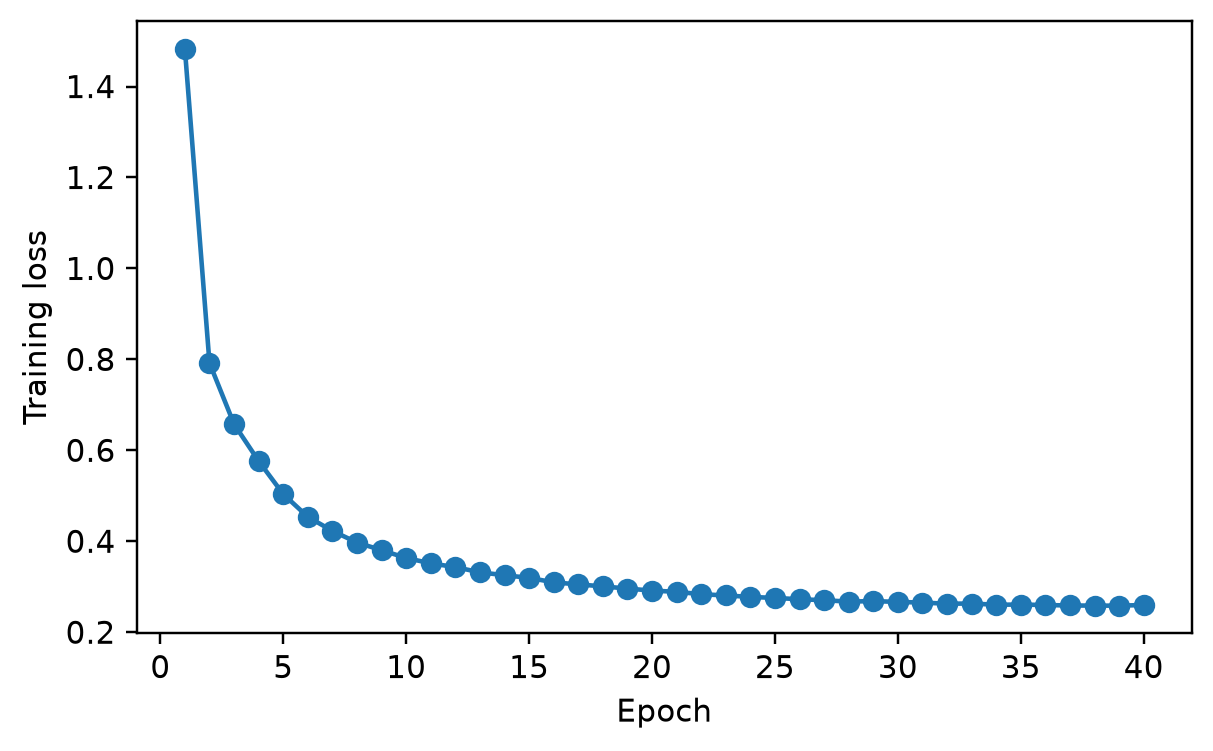

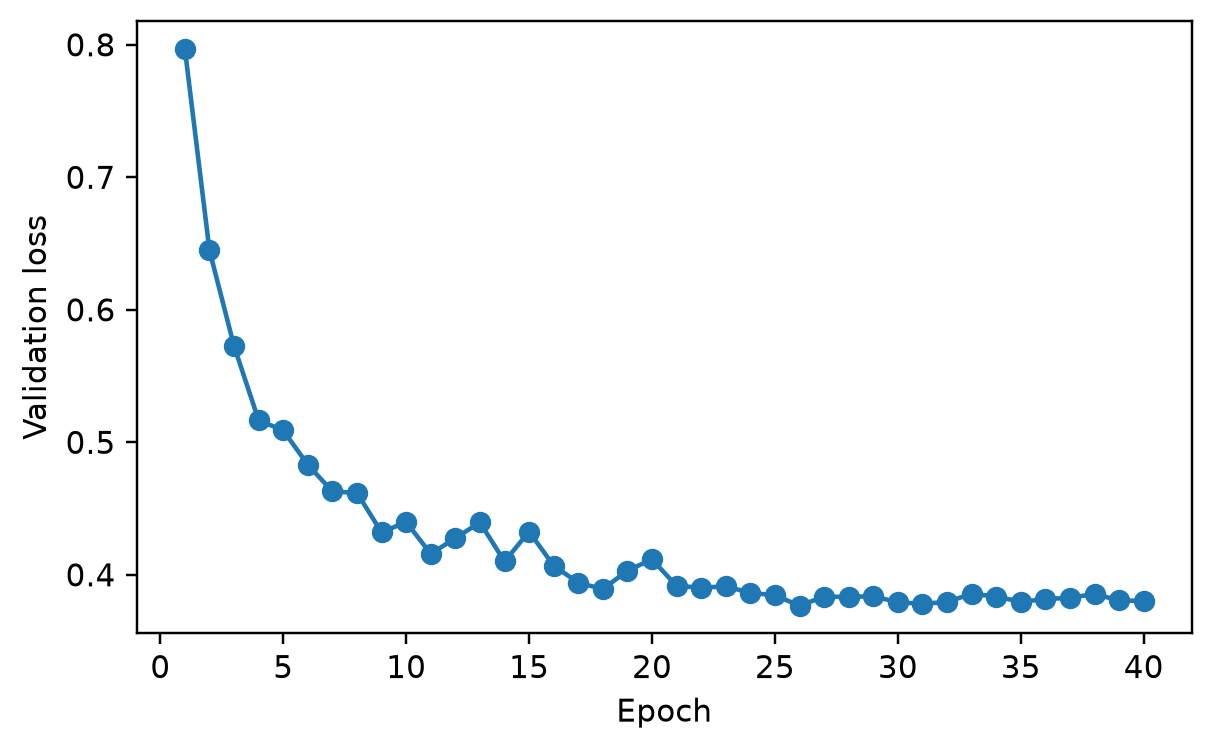

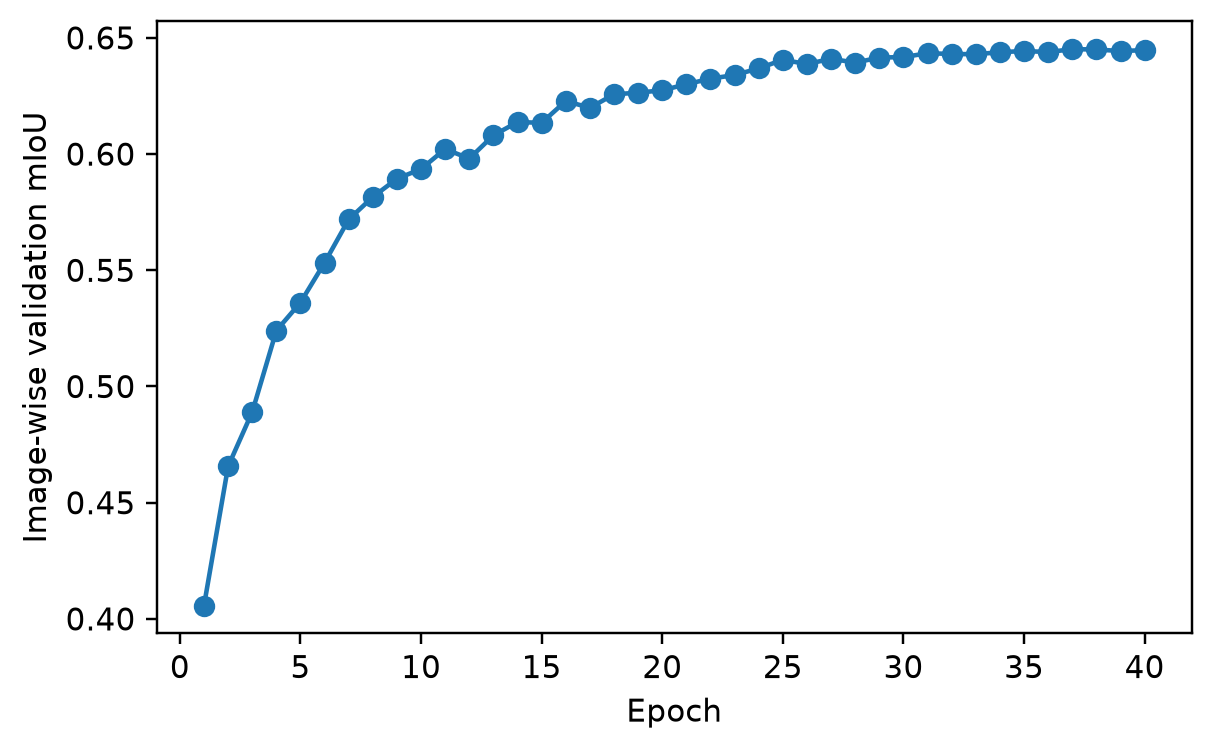

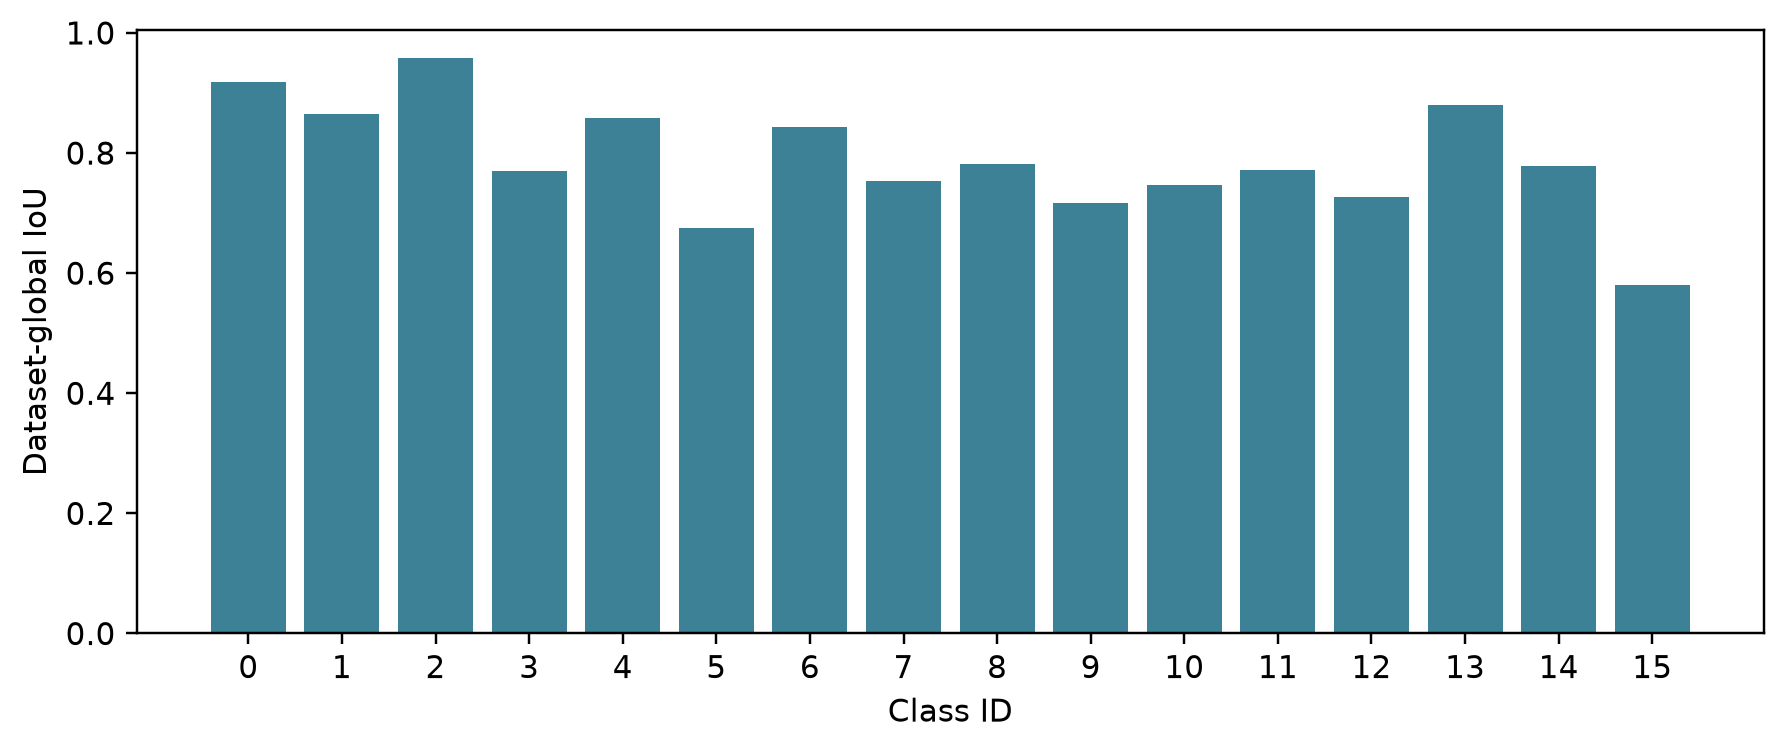

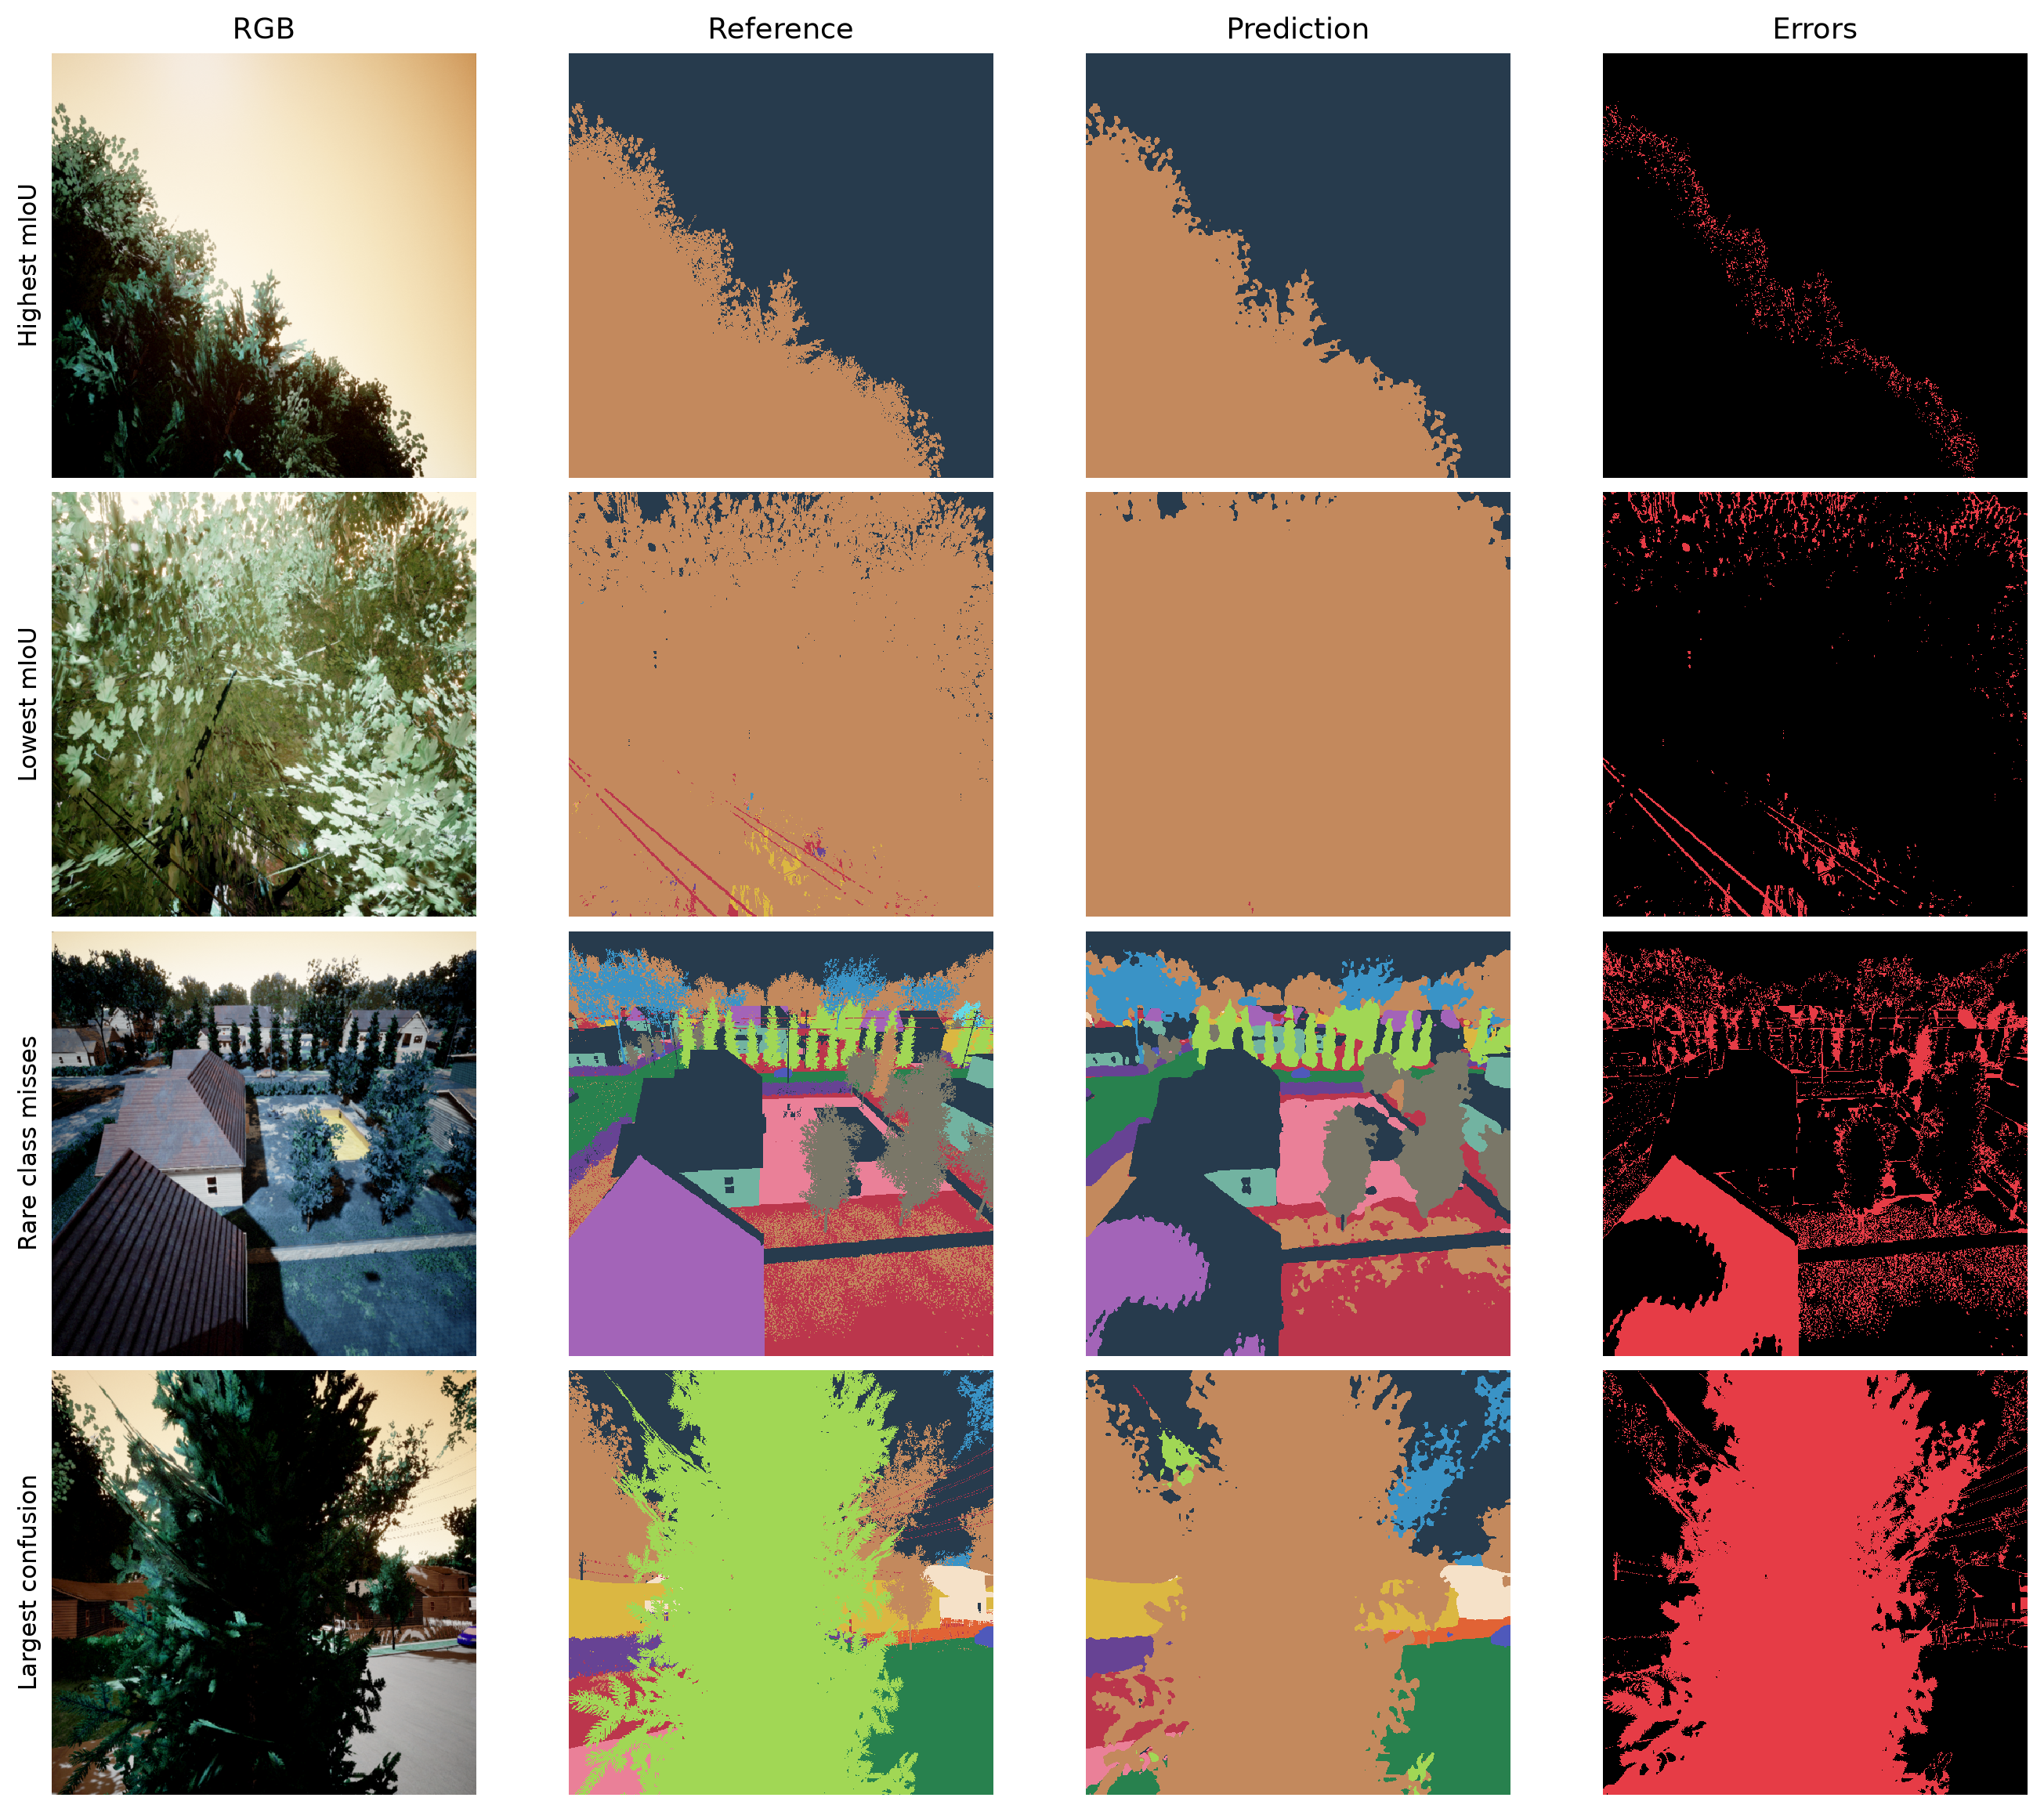

略過 20261125T182208Z_swin_upernet_residual_144257，缺少 metrics.json
略過 B5_512_hflip_20261123T151028Z，缺少 split.json


In [87]:
for run, best_path in trained_runs:
    state = load_checkpoint(best_path)
    summary = read_json(run / "summary.json")
    settings = state["config"]
    result_device = select_device(settings, "evaluate")
    result_model = create_model(settings["model"], initialize_pretrained=False).to(result_device)
    result_model.load_state_dict(state["model_state"])
    result_model.eval()
    save_validation(read_json(run / "metrics.json"), run)
    with (run / "epochs.csv").open(encoding="utf-8", newline="") as record:
        history = [{key: float(value) for key, value in row.items()} for row in csv.DictReader(record)]
    figure_dir = output_for(run, "figures")
    training_curves(history, figure_dir)
    representative_errors(result_model, validation_pairs(data_root, state), settings,
                          read_json(run / "metrics.json"), run, result_device, native=False)
    print(f"{run.name} | best epoch {summary['best_epoch']} | "
          f"validation mIoU {summary['image_miou']:.6f}")
    for figure in ("train_loss.png", "val_loss.png", "image_miou.png", "per_class_iou.png",
                   "prediction_examples.png"):
        display(DisplayImage(filename=str(figure_dir / figure), width=780))
    del result_model, state

if trained_runs:
    report_results(OUTPUTS)

## 11. Original-Resolution Inference and Test-Time Augmentation (TTA)

模型輸出先放大回原圖尺寸，再取每個像素的最高分類分數。TTA 會在翻轉或縮放後分別預測，把輸出轉回同一座標再平均。若要手動比較驗證效果，可打開下方開關並指定 best.pt。

In [88]:
def resize_logits(logits, size):
    return F.interpolate(logits, size=size, mode="bilinear", align_corners=False)


def tile_starts(length, tile, step):
    last = max(0, length - tile)
    starts = list(range(0, last + 1, step))
    if starts[-1] != last:
        starts.append(last)
    return starts


def tiled_logits(model, image, tile, overlap):
    if tile < 32 or not 0 <= overlap < 1:
        raise ValueError("Require tile_size >= 32 and 0 <= overlap < 1")
    height, width = image.shape[-2:]
    image = F.pad(image, (0, max(0, tile - width), 0, max(0, tile - height)),
                  mode="replicate")
    padded_h, padded_w = image.shape[-2:]
    step = max(1, int(tile * (1 - overlap)))
    coverage = image.new_zeros((padded_h, padded_w), dtype=torch.float32)
    total = None
    for y in tile_starts(padded_h, tile, step):
        for x in tile_starts(padded_w, tile, step):
            area = (..., slice(y, y + tile), slice(x, x + tile))
            logits = model(image[area]).float()
            if total is None:
                total = logits.new_zeros((*logits.shape[:2], padded_h, padded_w))
            total[area] += logits
            coverage[area] += 1
    return (total / coverage)[..., :height, :width]

In [89]:
@torch.inference_mode()
def predict_logits(model, image: Image.Image, config: dict, device):
    settings = config["inference"]
    original = (image.height, image.width)
    tile = settings["tile_size"]
    base_h, base_w = original if tile else resize_wh(config["image_size"])[::-1]
    flips = [()]
    for enabled, axis in ((settings["hflip"], -1), (settings["vflip"], -2)):
        if enabled:
            flips.append((axis,))
    scales = settings["scales"]
    if not scales or any(scale <= 0 for scale in scales):
        raise ValueError("inference.scales must contain positive factors")
    total = None
    for scale in scales:
        size = (max(32, round(base_w * scale)), max(32, round(base_h * scale)))
        tensor = image_tensor(image.resize(size, BILINEAR), config["normalize"])[None].to(device)
        for axes in flips:
            augmented = tensor.flip(axes) if axes else tensor
            logits = (tiled_logits(model, augmented, tile, settings["overlap"])
                      if tile else model(augmented)).float()
            restored = resize_logits(logits.flip(axes) if axes else logits, original)
            total = restored if total is None else total + restored
    return total / (len(scales) * len(flips))


def predict_mask(members, image, device):
    total = None
    for model, config, weight in members:
        probabilities = predict_logits(model, image, config, device).softmax(dim=1)
        weighted = probabilities * weight
        total = weighted if total is None else total + weighted
    return total[0].argmax(dim=0).cpu().numpy().astype("uint8")

In [90]:
@torch.inference_mode()
def evaluate_pairs(model, pairs, config, loss_function, device):
    model.eval()
    metrics = SegmentationMetrics()
    total = 0.0
    for pair in pairs:
        image, mask = read_pair(pair)
        logits = predict_logits(model, image, config, device)
        target = np.asarray(mask)
        labels = torch.from_numpy(target.astype(np.int64)).to(device)[None]
        total += loss_function(logits, labels).item()
        add_metrics(metrics, pair.image, target, logits[0].argmax(0).cpu().numpy())
    result = metrics.summary()
    result["val_loss"] = total / len(pairs)
    result["evaluation_size"] = "original resolution"
    return result


def load_trained(path, device, expected_kind):
    state = load_checkpoint(path)
    if state["dataset"] != expected_kind:
        raise ValueError(f"{path} was trained on {state['dataset']} data; expected {expected_kind}")
    config = state["config"]
    model = create_model(config["model"], initialize_pretrained=False).to(device)
    model.load_state_dict(state["model_state"])
    return model.eval(), state

In [91]:
def select_checkpoint(explicit_path, trained_runs):
    if explicit_path:
        return project_path(explicit_path)
    if not trained_runs:
        raise ValueError("Supply CHECKPOINT or enable RUN_TRAINING.")
    results = [(read_json(run / "summary.json"), path) for run, path in trained_runs]
    validation_grids = {
        (resize_wh(row["image_size"]), tuple(sorted(read_json(run / "split.json")["validation"])))
        for (run, _), (row, _) in zip(trained_runs, results, strict=True)
    }
    if len(validation_grids) != 1:
        raise ValueError("Set CHECKPOINT explicitly when validation images or grids differ.")
    return max(results, key=lambda result: result[0]["image_miou"])[1]


def evaluate_checkpoint(checkpoint, root, output_root, config, *, tta=True):
    device = select_device(config, "evaluate")
    if device.type == "cpu":
        torch.set_num_threads(min(torch.get_num_threads(), 4))
    model, state = load_trained(checkpoint, device, dataset_kind(root))
    settings = merge(state["config"], {"inference": config["inference"]})
    if tta:
        settings["inference"] = merge(settings["inference"], TTA_INFERENCE)
    reference = validation_pairs(root, state)
    loss = SegmentationLoss(**settings["loss"]).to(device)
    run = new_run(output_root, "tta" if tta else "native")
    write_json(run / "split.json", state["split"])
    write_json(run / "environment.json", {**environment(), "device": str(device),
                                         "started_at_utc": timestamp()})
    (run / "config.yaml").write_text(yaml.safe_dump(settings, sort_keys=False), encoding="utf-8")
    metrics = evaluate_pairs(model, reference, settings, loss, device)
    save_validation(metrics, run)
    representative_errors(model, reference, settings, metrics, run, device, native=True)
    write_json(run / "summary.json", {
        "mode": "evaluate", "source_mode": state["mode"], "dataset": state["dataset"],
        "checkpoint": str(checkpoint), "experiment": "B3" if tta else settings.get("experiment"),
        "inference_method": "tta" if tta else "baseline",
        "model": settings["model"]["name"], "seed": settings["seed"],
        "validation_images": len(reference), "image_miou": metrics["image_miou"],
        "global_miou": metrics["global_miou"], "evaluation_size": metrics["evaluation_size"],
        "finished_at_utc": timestamp(),
    })
    return run, metrics

In [92]:
CHECKPOINT = None  # 使用本次訓練的最佳權重，也可指定已完成的 best.pt
EVALUATE_NATIVE = True
COMPARE_TTA = True

if EVALUATE_NATIVE:
    checkpoint = select_checkpoint(CHECKPOINT, trained_runs)
    for use_tta in ([False, True] if COMPARE_TTA else [False]):
        native_run, native_metrics = evaluate_checkpoint(
            checkpoint, data_root, OUTPUTS, config, tta=use_tta,
        )
        print(f"TTA={use_tta}｜逐影像 mIoU={native_metrics['image_miou']:.6f}")

TTA=False｜逐影像 mIoU=0.644153
TTA=True｜逐影像 mIoU=0.647089


## 12. Generate the Kaggle Submission CSV

完成訓練並選定最佳 checkpoint 後才開啟寫檔。程式會推論 1,000 張正式測試圖，還原原始尺寸，輸出 img 欄與 16 個類別欄，並檢查檔名、欄位、RLE 範圍及完整像素覆蓋。RLE 採欄優先、從 1 開始，沒有該類別時寫 none。此節只輸出本機 CSV。

In [93]:
RLE_SYNTAX = re.compile(r"[1-9][0-9]*(?: [1-9][0-9]*)*")


def rle_encode(mask: np.ndarray) -> str:
    if mask.ndim != 2 or not np.isin(mask, (0, 1)).all():
        raise ValueError("RLE requires a two-dimensional binary mask")
    padded = np.pad(mask.ravel(order="F"), (1, 1))
    runs = np.flatnonzero(padded[1:] != padded[:-1]) + 1
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs)) if runs.size else "none"


def rle_decode(value: str, shape: tuple[int, int]) -> np.ndarray:
    pixels = np.zeros(shape[0] * shape[1], dtype=bool)
    if value == "none":
        return pixels.reshape(shape, order="F")
    if not RLE_SYNTAX.fullmatch(value):
        raise ValueError(f"Invalid RLE syntax: {value[:60]!r}")
    tokens = [int(x) for x in value.split()]
    if len(tokens) % 2:
        raise ValueError("RLE needs start-length pairs")
    previous_end = 0
    for start, length in zip(tokens[::2], tokens[1::2], strict=True):
        stop = start - 1 + length
        if start - 1 < previous_end or stop > pixels.size:
            raise ValueError("RLE runs overlap, are unsorted, or exceed image bounds")
        pixels[start - 1:stop] = True
        previous_end = stop
    return pixels.reshape(shape, order="F")


HEADER = ["img", *(f"class_{i}" for i in range(NUM_CLASSES))]


def prediction_filename(name):
    return name if Path(name).suffix == ".png" else f"{name}.png"


def encode_prediction(mask):
    if mask.ndim != 2 or mask.dtype.kind not in "ui" or mask.min() < 0 or mask.max() >= NUM_CLASSES:
        raise ValueError("Expected a two-dimensional class mask with labels 0–15")
    return [rle_encode(mask == label) for label in range(NUM_CLASSES)]


def decode_prediction(values, shape):
    if len(values) != NUM_CLASSES:
        raise ValueError("Expected 16 class RLE fields")
    assigned = np.zeros(shape, dtype=bool)
    result = np.zeros(shape, dtype=np.uint8)
    for label, value in enumerate(values):
        pixels = rle_decode(value, shape)
        if np.any(assigned & pixels):
            raise ValueError("Pixel assigned to more than one class")
        result[pixels] = label
        assigned |= pixels
    if not assigned.all():
        raise ValueError("Submission has unassigned pixels")
    return result

In [94]:
def validate_submission(path: Path, images, prediction_dir=None):
    shapes = {}
    for image in images:
        with Image.open(image) as source:
            shapes[image.name] = (source.height, source.width)
    if len(shapes) != len(images):
        raise ValueError("Duplicate expected filenames")
    pixels = max((height * width for height, width in shapes.values()), default=0)
    # A class can occupy every other pixel, with two integers per run.
    field_bound = ((pixels + 1) // 2) * (2 * len(str(pixels)) + 2)
    previous_limit = csv.field_size_limit()
    csv.field_size_limit(max(previous_limit, field_bound))
    try:
        return validate_submission_rows(path, shapes, prediction_dir)
    finally:
        csv.field_size_limit(previous_limit)


def validate_submission_rows(path, shapes, prediction_dir):
    seen = set()
    with path.open(newline="", encoding="utf-8") as stream:
        rows = csv.reader(stream)
        if next(rows, []) != HEADER:
            raise ValueError("CSV must have exactly the required 17 ordered columns")
        for row in rows:
            if len(row) != len(HEADER) or not all(row):
                raise ValueError("CSV row has missing or extra fields")
            name = row[0]
            if name in seen or name not in shapes:
                raise ValueError(f"Duplicate or unexpected filename: {name}")
            mask = decode_prediction(row[1:], shapes[name])
            if prediction_dir is not None:
                with Image.open(prediction_dir / prediction_filename(name)) as original:
                    if not np.array_equal(mask, np.asarray(original)):
                        raise ValueError(f"RLE round trip differs for {name}")
            seen.add(name)
    if seen != shapes.keys():
        raise ValueError(f"CSV is missing {len(shapes) - len(seen)} images")
    return len(seen)


def generate_submission(root, members, output, device, *, debug=False, prediction_dir=None, mask_fn=predict_mask):
    kind = dataset_kind(root)
    if kind != ("debug" if debug else "official"):
        raise ValueError("Checkpoint, dataset and submission modes must match")
    if debug and not output.name.startswith("debug_"):
        raise ValueError("Debug submission filename must start with debug_")
    if not debug:
        require_official(root)
    images = list_images(root / "test/imgs")
    if not images:
        raise ValueError("No test images")
    output.parent.mkdir(parents=True, exist_ok=True)
    if prediction_dir is not None:
        prediction_dir.mkdir(parents=True, exist_ok=True)
    temporary = None
    try:
        with NamedTemporaryFile(mode="w", newline="", encoding="utf-8",
                                dir=output.parent, delete=False) as stream:
            temporary = Path(stream.name)
            writer = csv.writer(stream)
            writer.writerow(HEADER)
            for path in images:
                with Image.open(path) as image:
                    mask = mask_fn(members, image.convert("RGB"), device)
                values = encode_prediction(mask)
                if not np.array_equal(decode_prediction(values, mask.shape), mask):
                    raise RuntimeError(f"RLE round trip failed for {path.name}")
                writer.writerow([path.name, *values])
                if prediction_dir is not None:
                    Image.fromarray(mask).save(prediction_dir / prediction_filename(path.name))
        count = validate_submission(temporary, images, prediction_dir)
        temporary.replace(output)
    finally:
        if temporary is not None:
            temporary.unlink(missing_ok=True)
    return count

In [95]:
def submit(config, root, checkpoint, output, *, debug=False, prediction_dir=None):
    kind = "debug" if debug else "official"
    device = select_device(config, "submit")
    if device.type == "cpu":
        torch.set_num_threads(min(torch.get_num_threads(), 4))
    model, state = load_trained(checkpoint, device, kind)
    if not debug and state["mode"] != "full":
        raise ValueError("Official submission requires a full-mode checkpoint")
    members = [(model, merge(state["config"], {"inference": config["inference"]}), 1.0)]
    for member in config.get("ensemble", []):
        other, other_state = load_trained(project_path(member["checkpoint"]), device, kind)
        if not debug and other_state["mode"] != "full":
            raise ValueError("Every official ensemble member must use a full-mode checkpoint")
        weight = float(member["weight"])
        if not 0 < weight < float("inf"):
            raise ValueError("Ensemble weights must be finite and positive")
        settings = merge(config["inference"], member.get("inference", {}))
        members.append((other, merge(other_state["config"], {"inference": settings}), weight))
    return generate_submission(root, members, output, device, debug=debug,
                               prediction_dir=prediction_dir)

In [96]:
WRITE_SUBMISSION = True # 設為 True 以產生 submission.csv，否則僅訓練與驗證

if WRITE_SUBMISSION:
    checkpoint = select_checkpoint(CHECKPOINT, trained_runs)
    submission_run = new_run(OUTPUTS, "submission")
    path = output_for(submission_run, "submissions") / "submission.csv"
    rows = submit(config, data_root, checkpoint, path)
    assert rows == validate_submission(path, test_images) == 1000
    print(f"CSV 驗證完成：{rows} 筆、{len(HEADER)} 欄｜{path}")

CSV 驗證完成：1000 筆、17 欄｜c:\Users\smile\Desktop\UAV\outputs\submissions\20261126T114839Z_submission_14730e\submission.csv
